In [1]:
%pip install gymnasium

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

### Objetivo

Implementar un agente de RL que aprenda a invertir en un entorno simulado con un único activo.

### Definición del entorno

El **estado** (observación) es una tupla de la forma ``(tendencia, posición)`` en la que:

- ``tendencia`` es la tendencia del precio, calculada a partir de las últimas 6 observaciones.

- ``posición`` es $1$ si el agente posee el activo y $0$ si no lo posee.

En cada momento, las **acciones** son:

- $0$ = vender

- $1$ = mantener

- $2$ = comprar

Obviamente, la acción *vender* sólo tendrá efecto si el agente es poseedor del activo, y la acción *comprar* sólo tendrá efecto cuando el agente no posee el activo.


In [3]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

### Funciones para generar precios

Se proponen cuatro funciones generadoras de precios. Las pruebas deben hacerse al menos con estas cuatro funciones. Si se desea, pueden añadirse otras funciones de diferentes características, o incluso probar con alguna serie de precios real.

#### 1. Tendencia suave + componente cíclica

In [4]:
def generar_precios(n_steps=1000):
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

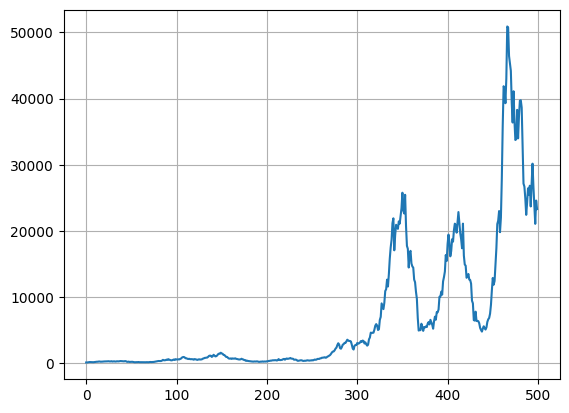

In [5]:
precios = generar_precios(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 2. Movimiento browniano

In [6]:
def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = np.random.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

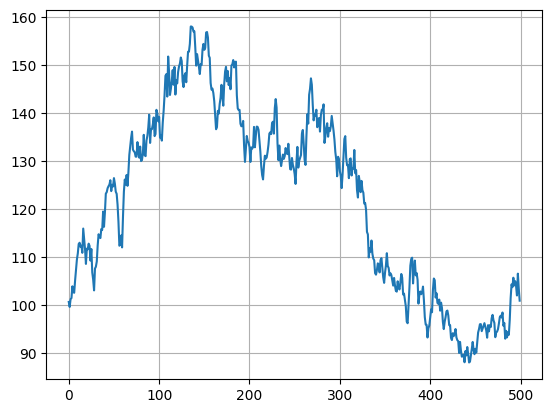

In [7]:
precios = generar_precios_browniano(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 3. Reversión a la media

In [8]:
def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

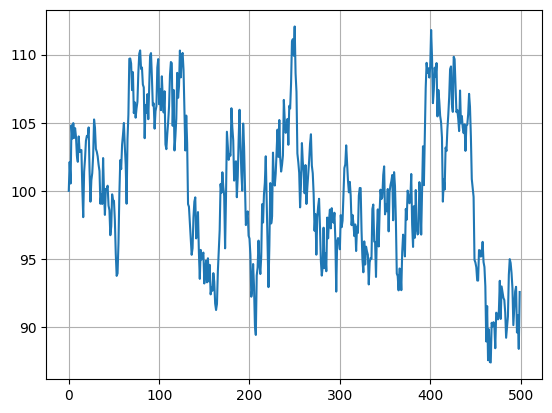

In [9]:
precios = generar_precios_reversion_media(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 4. Alternancia entre regímenes alcistas y bajistas

In [10]:
def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if np.random.rand() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = np.random.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = np.random.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios

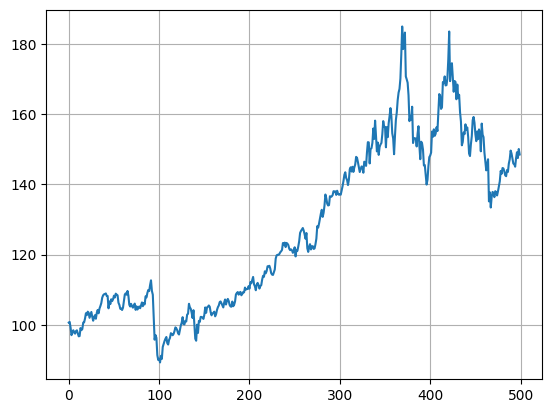

In [11]:
precios = generar_precios_regimenes(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

### Agente aleatorio

Como línea base, se proporciona un agente aleatorio que en cada instante selecciona la acción al azar. A continuación se compara su rendimiento en un episodio con la estrategia *buy & hold*.

In [12]:
n_steps = 500
prices = generar_precios(n_steps)
env = SimpleTradingEnv(prices)

obs, info = env.reset()
terminated = False
step_count = 0

balances = [env.balance]
actions_taken = []
positions = []

while not terminated:
    action = env.action_space.sample()
    positions.append(env.position)
    actions_taken.append(action)

    obs, reward, terminated, truncated, info = env.step(action)
    balances.append(env.balance)

positions = np.array(positions)
actions_taken = np.array(actions_taken)
valid_prices = prices[5:-1]

In [13]:
prices_on = valid_prices.copy()
prices_on[positions==0] = np.nan
prices_off = valid_prices.copy()
prices_off[positions==1] = np.nan

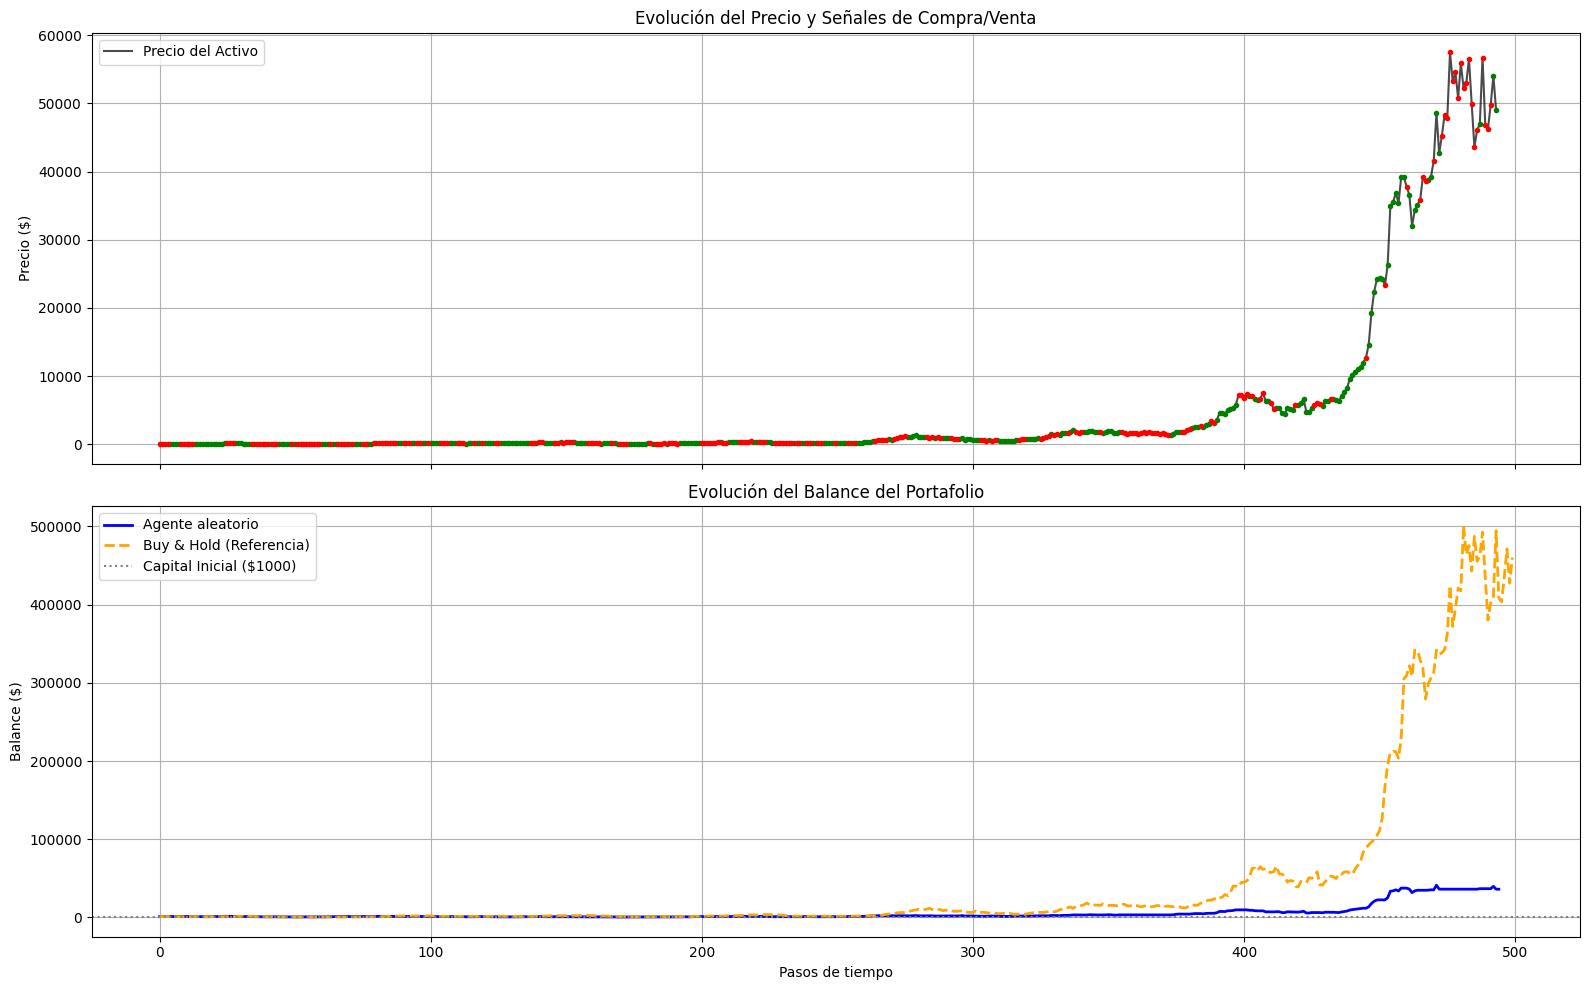

In [14]:
# --- Estrategia Buy & Hold para el panel de balance ---
bh_initial_cash = 1000.0
bh_start_price = prices[5]
bh_shares = (bh_initial_cash * 0.999) / bh_start_price
bh_balances = [bh_initial_cash if i < 5 else bh_shares * p for i, p in enumerate(prices)]

# --- Crear la figura con 2 Subgráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PANEL 1: Evolución del precio y señales de Trading
ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
ax1.plot(prices_on, 'g.')
ax1.plot(prices_off, 'r.')
ax1.set_title("Evolución del Precio y Señales de Compra/Venta")
ax1.set_ylabel("Precio ($)")
ax1.legend(loc="upper left")
ax1.grid(True)

# PANEL 2: Evolución del Balance (Portafolio)
ax2.plot(balances, label="Agente aleatorio", color="blue", linewidth=2)
ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")

ax2.set_title("Evolución del Balance del Portafolio")
ax2.set_xlabel("Pasos de tiempo")
ax2.set_ylabel("Balance ($)")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

### Ejercicios y notas sobre la implementación

1. Implementar los algoritmos vistos en clase y probarlos con distintas funciones de generación de los precios. Deben implementarse al menos los algoritmos *Q-Learning* y *Sarsa*, usando al menos las cuatro funciones de generación de precio propuestas.

   - Cada agente debe entrenarse con varios (muchos) episodios, y cada episodio debería usar una serie de precios distinta, aunque todas deberían ser generadas por la misma función. De este modo el agente puede aprender las regularidades de cada tipo de *mercado* sin repetir siempre los mismos datos para entrenar.

   - Para evaluar los agentes entrenados, se deberían usar datos de *test*, series de precios nuevas generadas a partir de la misma función usada durante el entrenamiento. Los resultados deberían promediarse sobre varias series de test.

2. Analizar las soluciones obtenidas para cada función de generación de precios, y compararlas con el agente aleatorio y con la estrategia *buy & hold*. Razonar si la estrategia encontrada en cada caso es la esperada.

3. Ajustar de manera adecuada los hiperparámetros de cada modelo, en particular el factor de aprendizaje $\alpha$, la tasa de exploración $\epsilon$ (probablemente con decaimiento temporal), el factor de descuento $\gamma$, y el número de episodios de entrenamiento.

4. Comparar en una tabla las soluciones obtenidas con cada algoritmo, incluyendo los *baselines*, sobre cada problema (función generadora de precios). Analizar al menos el rendimiento y el tiempo de convergencia.



### Entrega

Debe entregarse un documento en pdf de un **máximo de dos páginas** con un resumen de las pruebas realizadas, los resultados obtenidos y las conclusiones extraidas.

Las entregas se harán por grupos. Cada grupo de TFM realizará una entrega.

La fecha tope para la entrega es el **29/10/2026**, a las **23:59**.

**Importante:** Una primera versión del documento se deberá entregar por e-mail a luis.lago@uam.es antes de la clase del jueves 29 de octubre. En dicha clase cada grupo presentará su trabajo y lo discutirá con el profesor durante un máximo de 15 minutos. Los comentarios recibidos pueden usarse para mejorar el documento para la entrega final.

De cara a organizar las presentaciones, un representante de cada grupo debe enviar un e-mail al profesor antes del martes 27 de octubre. Ese mismo día os indicaré, mediante mensaje a los representantes, el orden de presentación.

### Evaluación

La realización de los ejercicios y pruebas propuestos garantiza el aprobado en la práctica (50%). El otro 50% se obtendrá valorando la realización de pruebas que vayan más allá de los mínimos planteados (10%), la calidad de presentación de los resultados (20%), la justificación de las decisiones de diseño tomadas (10%) y el análisis crítico de las soluciones obtenidas (10%).

## Solución

### Fase 0: Preparación

Se usan sin modificar el entorno `SimpleTradingEnv` y las cuatro funciones generadoras de precios definidas arriba.

Cada episodio es una serie de precios completa. Para que entrenamiento, validación y test nunca compartan series, cada conjunto se genera con un rango de semillas distinto:

| Conjunto | Series por generador | Uso |
|---|---|---|
| Entrenamiento | una nueva en cada episodio | aprendizaje del agente |
| Validación | 50 (fijas) | curvas de aprendizaje y ajuste de hiperparámetros |
| Test | 200 (fijas) | evaluación final |
| Discretización | 100 (fijas) | cálculo de los cortes de la tendencia |

In [15]:
import time
import pandas as pd

# --- Configuración general ---
N_STEPS = 500

GENERADORES = {
    "ciclo": generar_precios,
    "browniano": generar_precios_browniano,
    "reversion": generar_precios_reversion_media,
    "regimenes": generar_precios_regimenes,
}

# Rangos de semillas disjuntos para cada conjunto
SEMILLA_TRAIN = 0
SEMILLA_VAL = 10_000
SEMILLA_TEST = 20_000
SEMILLA_DISC = 30_000

N_VAL = 50
N_TEST = 200
N_DISC = 100

#### Generación de series reproducibles

In [16]:
def generar_serie(nombre_generador, semilla, n_steps=N_STEPS):
    """
    Genera una serie de precios reproducible con una de las funciones propuestas.
    Las funciones usan el estado global de np.random, así que se fija la semilla justo antes de llamarlas.
    """
    np.random.seed(semilla)
    return GENERADORES[nombre_generador](n_steps=n_steps)


def generar_conjunto(nombre_generador, semilla_inicial, n_series):
    return [generar_serie(nombre_generador, semilla_inicial + i) for i in range(n_series)]

In [17]:
SERIES_VAL = {g: generar_conjunto(g, SEMILLA_VAL, N_VAL) for g in GENERADORES}
SERIES_TEST = {g: generar_conjunto(g, SEMILLA_TEST, N_TEST) for g in GENERADORES}
SERIES_DISC = {g: generar_conjunto(g, SEMILLA_DISC, N_DISC) for g in GENERADORES}

#### Ejecución de un episodio

Mismo bucle que el del agente aleatorio de arriba, pero con la política como parámetro: una función `politica(obs, env)` que devuelve la acción. Así se usa el mismo código para los *baselines* y para los agentes de RL.

In [18]:
def jugar_episodio(prices, politica, semilla=None):
    env = SimpleTradingEnv(prices)
    obs, info = env.reset()
    if semilla is not None:
        env.action_space.seed(semilla)
    terminated = False

    balances = [env.balance]
    actions_taken = []
    positions = []

    while not terminated:
        action = politica(obs, env)
        positions.append(env.position)
        actions_taken.append(action)

        obs, reward, terminated, truncated, info = env.step(action)
        balances.append(env.balance)

    return np.array(balances), np.array(actions_taken), np.array(positions)

#### Baselines

- **Agente aleatorio**: el mismo del notebook, `env.action_space.sample()`.
- **Buy & hold**: compra en el primer paso y mantiene hasta el final.

In [19]:
def politica_aleatoria(obs, env):
    return env.action_space.sample()


def politica_buy_and_hold(obs, env):
    return 2 if env.position == 0 else 1

#### Evaluación

Para cada serie se juega un episodio y se calculan:

- Balance final (el capital inicial es 1000).
- Si supera al *buy & hold* en esa misma serie (calculado con la fórmula del notebook).
- Número de operaciones efectivas (compras y ventas que realmente se ejecutan).
- Porcentaje de pasos con el activo en cartera.
- Rentabilidad logarítmica media, `mean(log(balance_final / 1000))`. Equivale a la rentabilidad geométrica y, a diferencia del balance medio, no la dominan las pocas series del generador *ciclo* que multiplican el capital por cientos. Es la métrica que se usa para ajustar hiperparámetros y medir la convergencia.

In [20]:
def evaluar(politica, lista_series, semilla=None):
    finales, gana_bh, n_ops, invertido = [], [], [], []

    for i, prices in enumerate(lista_series):
        semilla_ep = None if semilla is None else semilla + i
        balances, acciones, posiciones = jugar_episodio(prices, politica, semilla_ep)

        # Buy & hold de referencia, misma fórmula que en el notebook
        bh_shares = (1000.0 * 0.999) / prices[5]
        bh_final = bh_shares * prices[-1]

        # Compras y ventas que realmente se ejecutan
        compra = (acciones == 2) & (posiciones == 0)
        venta = (acciones == 0) & (posiciones == 1)

        # Posición mantenida durante cada paso (después de ejecutar la acción)
        pos_paso = posiciones.copy()
        pos_paso[compra] = 1
        pos_paso[venta] = 0

        finales.append(balances[-1])
        gana_bh.append(balances[-1] > bh_final)
        n_ops.append(compra.sum() + venta.sum())
        invertido.append(pos_paso.mean())

    finales = np.array(finales)
    return {
        "balance_medio": finales.mean(),
        "balance_std": finales.std(),
        "balance_mediana": np.median(finales),
        "ret_log_medio": np.mean(np.log(finales / 1000.0)),
        "pct_gana_bh": 100 * np.mean(gana_bh),
        "operaciones": np.mean(n_ops),
        "pct_invertido": 100 * np.mean(invertido),
        "finales": finales,
    }

#### Comprobación con los baselines sobre validación

In [21]:
# El buy & hold ejecutado en el entorno debe coincidir con la fórmula del notebook
for g in GENERADORES:
    for prices in SERIES_VAL[g]:
        balances, _, _ = jugar_episodio(prices, politica_buy_and_hold)
        bh_formula = (1000.0 * 0.999) / prices[5] * prices[-1]
        assert np.isclose(balances[-1], bh_formula)
print("Buy & hold en el entorno = fórmula del notebook")

filas = []
for g in GENERADORES:
    t0 = time.perf_counter()
    res_rand = evaluar(politica_aleatoria, SERIES_VAL[g], semilla=SEMILLA_VAL)
    t_episodio = (time.perf_counter() - t0) / N_VAL

    res_bh = evaluar(politica_buy_and_hold, SERIES_VAL[g])

    for nombre, res in [("Aleatorio", res_rand), ("Buy & hold", res_bh)]:
        filas.append({"generador": g, "agente": nombre,
                      **{k: v for k, v in res.items() if k != "finales"}})

    print(f"{g}: {1000 * t_episodio:.1f} ms por episodio")

pd.DataFrame(filas).round(2)

Buy & hold en el entorno = fórmula del notebook


ciclo: 6.9 ms por episodio


browniano: 8.1 ms por episodio


reversion: 6.9 ms por episodio


regimenes: 9.1 ms por episodio


,generador,agente,balance_medio,balance_std,balance_mediana,ret_log_medio,pct_gana_bh,operaciones,pct_invertido
0,ciclo,Aleatorio,23123.30,80255.49,4863.37,1.60,18.0,166.58,49.28
1,ciclo,Buy & hold,106284.82,195767.50,18198.41,3.11,0.0,1.00,100.00
2,browniano,Aleatorio,883.05,290.43,855.18,-0.17,44.0,166.58,49.28
3,browniano,Buy & hold,962.01,374.29,852.13,-0.11,0.0,1.00,100.00
4,reversion,Aleatorio,955.31,244.35,924.03,-0.08,34.0,166.58,49.28
5,reversion,Buy & hold,1015.13,71.99,1012.77,0.01,0.0,1.00,100.00
6,regimenes,Aleatorio,801.57,207.66,837.06,-0.26,42.0,166.58,49.28
7,regimenes,Buy & hold,898.22,393.52,857.14,-0.21,0.0,1.00,100.00


### Fase 1: Discretización de la tendencia

Q-Learning y Sarsa tabulares necesitan un número finito de estados. La posición ya es discreta (0 o 1), pero la tendencia es un valor continuo, así que se divide en intervalos y cada intervalo pasa a ser un estado.

Primero se mira qué valores toma realmente la tendencia en cada generador, recorriendo con el entorno las series reservadas para la discretización. La tendencia no depende de las acciones, así que basta con mantener en todos los pasos.

In [22]:
def tendencias_serie(prices):
    """Tendencia observada en cada paso de un episodio, tal como la calcula el entorno."""
    env = SimpleTradingEnv(prices)
    obs, info = env.reset()
    terminated = False
    tendencias = [obs[0]]
    while not terminated:
        obs, reward, terminated, truncated, info = env.step(1)
        tendencias.append(obs[0])
    return np.array(tendencias)


TENDENCIAS_DISC = {g: np.concatenate([tendencias_serie(p) for p in SERIES_DISC[g]]) for g in GENERADORES}

resumen = []
for g, t in TENDENCIAS_DISC.items():
    resumen.append({
        "generador": g,
        "observaciones": len(t),
        "min": t.min(),
        "p1": np.percentile(t, 1),
        "p50": np.percentile(t, 50),
        "p99": np.percentile(t, 99),
        "max": t.max(),
        # Intervalos iguales sobre [-1, 1]: con 10, los dos centrales son [-0.2, 0) y [0, 0.2)
        "% en los 2 intervalos centrales de [-1, 1]": 100 * np.mean(np.abs(t) < 0.2),
    })
pd.DataFrame(resumen).round(4)

,generador,observaciones,min,p1,p50,p99,max,"% en los 2 intervalos centrales de [-1, 1]"
0,ciclo,49500,-0.5271,-0.3166,0.0202,0.3779,0.7301,80.1313
1,browniano,49500,-0.0955,-0.0574,-0.0004,0.0582,0.1159,100.0000
2,reversion,49500,-0.0975,-0.0569,0.0001,0.0575,0.1032,100.0000
3,regimenes,49500,-0.1339,-0.0668,0.0003,0.0582,0.1147,100.0000


Con 10 intervalos iguales sobre $[-1, 1]$ prácticamente todas las observaciones caen en los dos intervalos centrales, y el agente solo distinguiría si la tendencia es positiva o negativa. Por eso los cortes se ponen en los **cuantiles** de la tendencia observada, calculados por separado para cada generador: así cada intervalo recibe aproximadamente el mismo número de visitas.

In [23]:
N_INTERVALOS = 10


def calcular_cortes(tendencias, n_intervalos=N_INTERVALOS):
    """Cortes interiores (n_intervalos - 1) en los cuantiles de la tendencia."""
    return np.quantile(tendencias, np.linspace(0, 1, n_intervalos + 1)[1:-1])


CORTES = {g: calcular_cortes(TENDENCIAS_DISC[g]) for g in GENERADORES}

pd.DataFrame(CORTES).T.round(4)

,0,1,2,3,4,5,6,7,8
ciclo,-0.1740,-0.1104,-0.0608,-0.0191,0.0202,0.0600,0.1030,0.1526,0.2200
browniano,-0.0321,-0.0212,-0.0134,-0.0067,-0.0004,0.0059,0.0128,0.0208,0.0319
reversion,-0.0311,-0.0203,-0.0128,-0.0060,0.0001,0.0062,0.0128,0.0205,0.0313
regimenes,-0.0307,-0.0170,-0.0095,-0.0043,0.0003,0.0048,0.0096,0.0155,0.0250


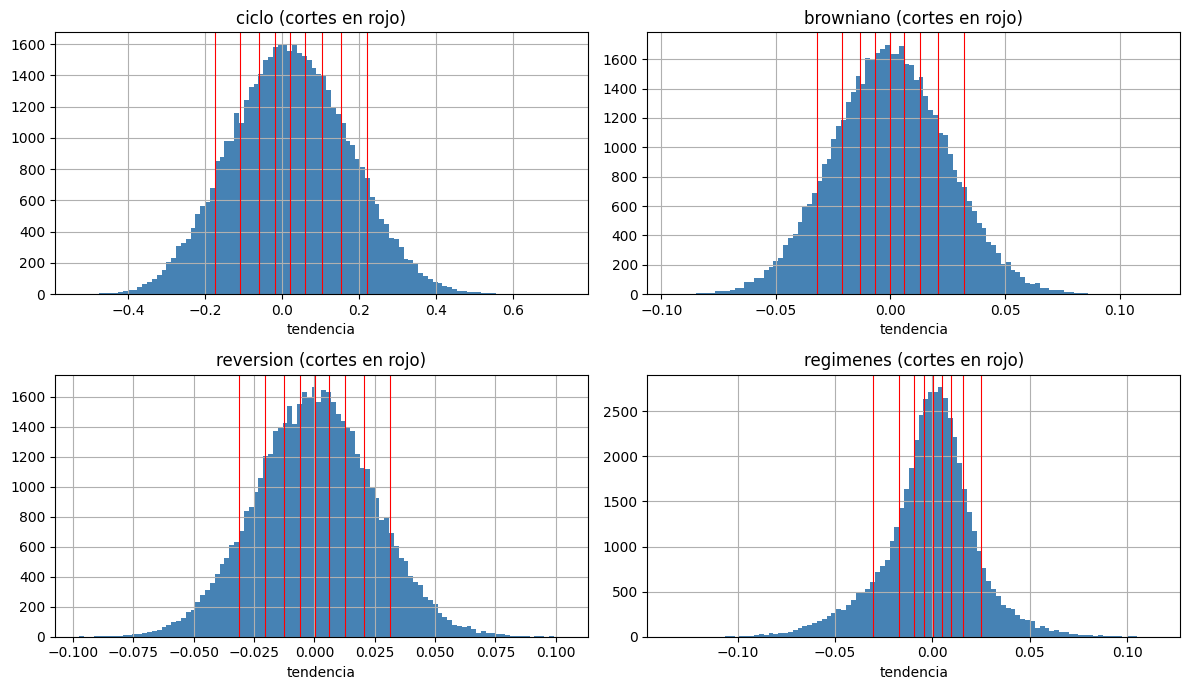

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, g in zip(axes.flat, GENERADORES):
    t = TENDENCIAS_DISC[g]
    ax.hist(t, bins=100, color="steelblue")
    for c in CORTES[g]:
        ax.axvline(c, color="red", linewidth=0.8)
    ax.set_title(f"{g} (cortes en rojo)")
    ax.set_xlabel("tendencia")
    ax.grid()

plt.tight_layout()
plt.show()

#### Del estado del entorno al estado de la tabla Q

El estado discreto combina el intervalo de la tendencia y la posición:

`estado = posicion * N_INTERVALOS + intervalo`

Con 10 intervalos hay 20 estados: del 0 al 9 sin el activo y del 10 al 19 con el activo.

In [25]:
def discretizar(obs, cortes):
    intervalo = int(np.searchsorted(cortes, obs[0], side="right"))
    posicion = int(obs[1])
    return posicion * (len(cortes) + 1) + intervalo


N_ESTADOS = 2 * N_INTERVALOS
N_ACCIONES = 3

# Ejemplo
obs, _ = SimpleTradingEnv(SERIES_VAL["browniano"][0]).reset()
print("obs:", obs, "-> estado:", discretizar(obs, CORTES["browniano"]))

obs: [-0.00755097  0.        ] -> estado: 3


#### Comprobación sobre series nuevas

Los cortes se han calculado con las series de discretización. Se comprueba con las series de validación que el reparto entre intervalos se mantiene en series que no se usaron para calcularlos (lo ideal es un 10% en cada uno).

In [26]:
reparto = {}
for g in GENERADORES:
    t_val = np.concatenate([tendencias_serie(p) for p in SERIES_VAL[g]])
    intervalos = np.searchsorted(CORTES[g], t_val, side="right")
    reparto[g] = 100 * np.bincount(intervalos, minlength=N_INTERVALOS) / len(intervalos)

pd.DataFrame(reparto, index=[f"intervalo {i}" for i in range(N_INTERVALOS)]).T.round(1)

,intervalo 0,intervalo 1,intervalo 2,intervalo 3,intervalo 4,intervalo 5,intervalo 6,intervalo 7,intervalo 8,intervalo 9
ciclo,10.1,10.0,10.6,10.2,9.6,9.8,9.9,9.8,9.9,10.1
browniano,9.6,10.4,10.1,10.1,10.0,10.6,10.0,10.0,9.8,9.4
reversion,9.6,10.1,9.8,10.2,9.9,10.4,10.4,10.0,10.0,9.6
regimenes,9.7,10.2,10.0,9.4,10.2,10.2,10.3,10.1,10.3,9.6


### Fase 2: Q-Learning y Sarsa

Los dos algoritmos mantienen una tabla $Q(s, a)$ de `N_ESTADOS` × `N_ACCIONES`, eligen acciones con una política $\epsilon$-greedy y, tras cada paso, actualizan

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left[ \text{objetivo} - Q(s, a) \right]$$

La única diferencia es el valor futuro que usan en el objetivo:

| Algoritmo | Objetivo | Tipo |
|---|---|---|
| Q-Learning | $r + \gamma \max_{a'} Q(s', a')$ | *off-policy*: usa la mejor acción en $s'$ |
| Sarsa | $r + \gamma \, Q(s', a')$, con $a'$ la acción que se va a ejecutar | *on-policy*: usa la acción elegida con $\epsilon$-greedy |

En el último paso del episodio el objetivo es solo $r$.

#### Política $\epsilon$-greedy

- Con probabilidad $\epsilon$ se elige una acción al azar (exploración) y, si no, la de mayor $Q$ (explotación). Los empates se deshacen al azar, para que al principio, con la tabla a cero, no se elija siempre la acción 0.
- $\epsilon$ baja linealmente de `eps_inicial` a `eps_final` a lo largo de una fracción `frac_exploracion` de los episodios, y después se queda en `eps_final`.
- La exploración usa su propio generador aleatorio (`np.random.default_rng`), independiente del que genera las series de precios.

In [27]:
def elegir_accion(Q, estado, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(N_ACCIONES))
    q = Q[estado]
    return int(rng.choice(np.flatnonzero(q == q.max())))


def epsilon_episodio(episodio, n_episodios, eps_inicial, eps_final, frac_exploracion):
    n_decaimiento = max(1, int(frac_exploracion * n_episodios))
    frac = min(1.0, episodio / n_decaimiento)
    return eps_inicial + frac * (eps_final - eps_inicial)


def acciones_efectivas(Q):
    """
    Acción voraz de cada estado agrupando las que son equivalentes:
    sin activo, vender = mantener (fuera); con activo, comprar = mantener (dentro).
    Devuelve 0 = vende, 1 = mantiene la posición, 2 = compra.
    """
    a = Q.argmax(1)
    n = len(a) // 2
    ef = np.ones_like(a)
    ef[:n][a[:n] == 2] = 2
    ef[n:][a[n:] == 0] = 0
    return ef


def politica_voraz(Q, cortes):
    """Política aprendida, sin exploración, con la interfaz de jugar_episodio."""
    def politica(obs, env):
        return int(np.argmax(Q[discretizar(obs, cortes)]))
    return politica

#### Entrenamiento

Una única función para los dos algoritmos (`metodo="qlearning"` o `metodo="sarsa"`).

- Cada episodio usa una serie nueva del mismo generador. Las semillas de entrenamiento empiezan en `SEMILLA_TRAIN` y no llegan a las de validación; cada repetición del entrenamiento (`repeticion`) usa otro bloque de semillas y otra semilla de exploración.
- Si se pasan series de validación, cada `cada` episodios se para el entrenamiento y se juega la política voraz actual sobre ellas. Esos puntos forman la curva de aprendizaje.
- También se guarda la recompensa total de cada episodio de entrenamiento, el número de estados en los que cambia la política entre evaluaciones y el tiempo de entrenamiento (sin contar las evaluaciones).

In [28]:
def entrenar(metodo, nombre_generador, cortes, n_episodios=1000,
             alpha=0.05, gamma=0.9,
             eps_inicial=1.0, eps_final=0.01, frac_exploracion=0.8,
             repeticion=0, series_val=None, cada=100):
    assert metodo in ("qlearning", "sarsa")
    assert n_episodios <= SEMILLA_VAL - SEMILLA_TRAIN  # las series de entrenamiento no pisan las de validación

    rng = np.random.default_rng(repeticion)
    Q = np.zeros((2 * (len(cortes) + 1), N_ACCIONES))
    recompensas = []
    curva = []
    politica_anterior = None
    tiempo_eval = 0.0
    t0 = time.perf_counter()

    for ep in range(n_episodios):
        prices = generar_serie(nombre_generador, SEMILLA_TRAIN + 1_000_000 * repeticion + ep)
        env = SimpleTradingEnv(prices)
        epsilon = epsilon_episodio(ep, n_episodios, eps_inicial, eps_final, frac_exploracion)

        obs, info = env.reset()
        s = discretizar(obs, cortes)
        a = elegir_accion(Q, s, epsilon, rng)
        terminated = False
        total = 0.0

        while not terminated:
            obs, reward, terminated, truncated, info = env.step(a)
            s2 = discretizar(obs, cortes)
            a2 = elegir_accion(Q, s2, epsilon, rng)

            if terminated:
                objetivo = reward
            elif metodo == "qlearning":
                objetivo = reward + gamma * Q[s2].max()
            else:
                objetivo = reward + gamma * Q[s2, a2]

            Q[s, a] += alpha * (objetivo - Q[s, a])
            s, a = s2, a2
            total += reward

        recompensas.append(total)

        if series_val is not None and (ep + 1) % cada == 0:
            t_eval = time.perf_counter()
            res = evaluar(politica_voraz(Q, cortes), series_val)
            politica = acciones_efectivas(Q)
            cambios = np.nan if politica_anterior is None else int((politica != politica_anterior).sum())
            politica_anterior = politica
            curva.append({"episodio": ep + 1, "epsilon": epsilon, "cambios_politica": cambios,
                          **{k: v for k, v in res.items() if k != "finales"}})
            tiempo_eval += time.perf_counter() - t_eval

    return {
        "Q": Q,
        "recompensas": np.array(recompensas),
        "curva": pd.DataFrame(curva),
        "tiempo": time.perf_counter() - t0 - tiempo_eval,  # sin contar las evaluaciones
    }

#### Primera prueba

Entrenamiento corto (1000 episodios) de los dos algoritmos con los cuatro generadores, con hiperparámetros por defecto, solo para comprobar que el código funciona y que el agente aprende algo. El ajuste de hiperparámetros y el análisis de la convergencia se hacen en las fases siguientes.

In [29]:
PRUEBA = {}
for g in GENERADORES:
    for metodo in ("qlearning", "sarsa"):
        PRUEBA[(g, metodo)] = entrenar(metodo, g, CORTES[g], n_episodios=1000, series_val=SERIES_VAL[g], cada=100)
        print(f"{g:10s} {metodo:10s} {PRUEBA[(g, metodo)]['tiempo']:.1f} s")

ciclo      qlearning  12.8 s


ciclo      sarsa      10.2 s


browniano  qlearning  12.6 s


browniano  sarsa      10.5 s


reversion  qlearning  11.8 s


reversion  sarsa      10.7 s


regimenes  qlearning  11.3 s


regimenes  sarsa      10.9 s


In [30]:
filas = []
for g in GENERADORES:
    referencias = {
        "Aleatorio": evaluar(politica_aleatoria, SERIES_VAL[g], semilla=SEMILLA_VAL),
        "Buy & hold": evaluar(politica_buy_and_hold, SERIES_VAL[g]),
    }
    for nombre, res in referencias.items():
        filas.append({"generador": g, "agente": nombre, **{k: v for k, v in res.items() if k != "finales"}})
    for metodo in ("qlearning", "sarsa"):
        final = PRUEBA[(g, metodo)]["curva"].iloc[-1]
        filas.append({"generador": g, "agente": metodo,
                      **{k: final[k] for k in ("balance_medio", "balance_std", "balance_mediana",
                                               "pct_gana_bh", "operaciones", "pct_invertido")}})

pd.DataFrame(filas).round(2)

,generador,agente,balance_medio,balance_std,balance_mediana,ret_log_medio,pct_gana_bh,operaciones,pct_invertido
0,ciclo,Aleatorio,23123.30,80255.49,4863.37,1.60,18.0,166.58,49.28
1,ciclo,Buy & hold,106284.82,195767.50,18198.41,3.11,0.0,1.00,100.00
2,ciclo,qlearning,425569.90,822590.18,148607.45,NaN,82.0,79.50,35.76
3,ciclo,sarsa,1048619.62,1804625.23,471296.45,NaN,94.0,29.80,42.44
4,browniano,Aleatorio,883.05,290.43,855.18,-0.17,44.0,166.58,49.28
5,browniano,Buy & hold,962.01,374.29,852.13,-0.11,0.0,1.00,100.00
6,browniano,qlearning,1000.00,0.00,1000.00,NaN,62.0,0.00,0.00
7,browniano,sarsa,1000.00,0.00,1000.00,NaN,62.0,0.00,0.00
8,reversion,Aleatorio,955.31,244.35,924.03,-0.08,34.0,166.58,49.28
9,reversion,Buy & hold,1015.13,71.99,1012.77,0.01,0.0,1.00,100.00


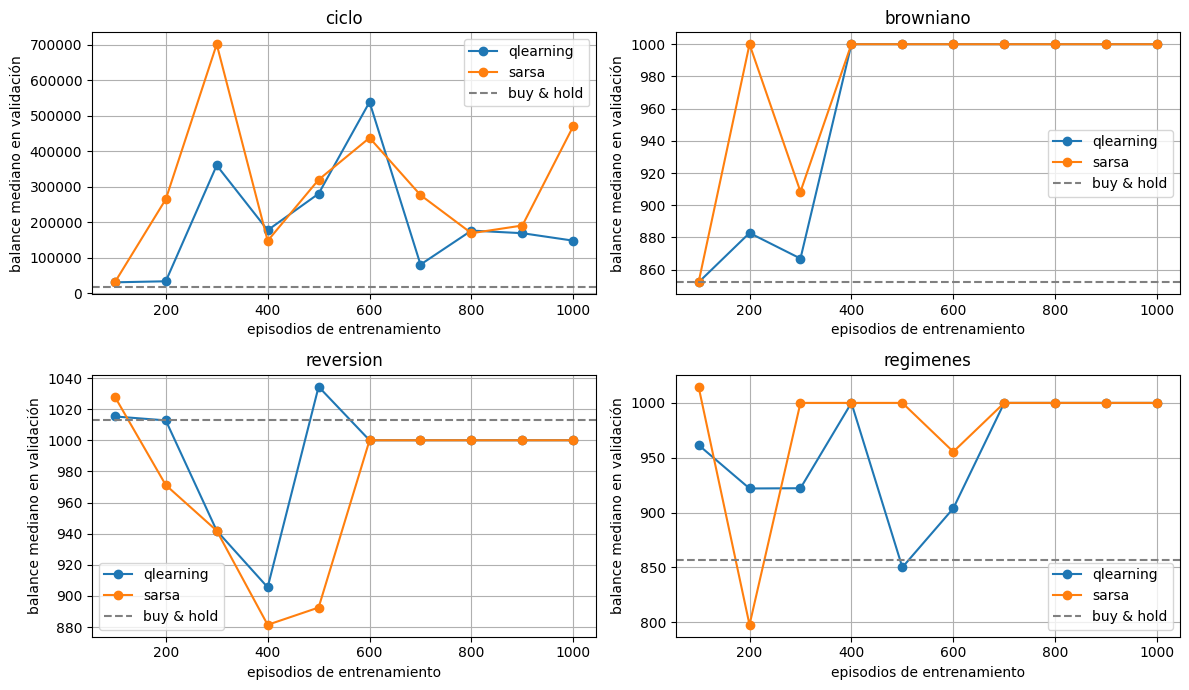

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))

for ax, g in zip(axes.flat, GENERADORES):
    for metodo in ("qlearning", "sarsa"):
        curva = PRUEBA[(g, metodo)]["curva"]
        ax.plot(curva["episodio"], curva["balance_mediana"], marker="o", label=metodo)
    bh = evaluar(politica_buy_and_hold, SERIES_VAL[g])["balance_mediana"]
    ax.axhline(bh, color="gray", linestyle="--", label="buy & hold")
    ax.set_title(g)
    ax.set_xlabel("episodios de entrenamiento")
    ax.set_ylabel("balance mediano en validación")
    ax.grid()
    ax.legend()

plt.tight_layout()
plt.show()

### Fase 3: Ajuste de hiperparámetros

La primera prueba muestra que con $\alpha = 0.05$ el agente no encuentra la estrategia en *reversión* aunque la señal existe, así que los hiperparámetros importan. Se ajustan sobre las series de **validación**, nunca sobre las de test.

**Protocolo**

- Búsqueda por coordenadas: se ajusta un hiperparámetro cada vez, manteniendo los demás en el mejor valor encontrado hasta ese momento. Orden: $\alpha$, $\gamma$, decaimiento de $\epsilon$ y discretización.
- El ajuste se hace por separado para cada generador y cada algoritmo.
- Cada configuración se entrena 2 veces (repeticiones 0 y 1) con 3000 episodios, evaluando cada 250.
- Puntuación: rentabilidad logarítmica media en validación, promediada en las 4 últimas evaluaciones (episodios 2250 a 3000) y en las 2 repeticiones. Promediar varias evaluaciones reduce el ruido de quedarse con un único punto de la curva.
- Los entrenamientos se lanzan en paralelo con `joblib`.
- Si varios valores empatan (por ejemplo, todos llevan a no operar nunca), se queda el primero de la lista.

In [32]:
from joblib import Parallel, delayed

ALGORITMOS = ("qlearning", "sarsa")
N_EP_AJUSTE = 3000
CADA_AJUSTE = 250
REPS_AJUSTE = (0, 1)

CONFIG_BASE = {"alpha": 0.05, "gamma": 0.9, "frac_exploracion": 0.8, "discretizacion": "cuantiles 10"}


def cortes_config(nombre_generador, discretizacion):
    """'cuantiles n': cortes en los cuantiles de la tendencia; 'uniforme n': n intervalos iguales en [-1, 1]."""
    tipo, n = discretizacion.split()
    n = int(n)
    if tipo == "uniforme":
        return np.linspace(-1, 1, n + 1)[1:-1]
    return calcular_cortes(TENDENCIAS_DISC[nombre_generador], n)


def tarea(g, metodo, config, repeticion, n_episodios, cada, series_val):
    return dict(metodo=metodo, nombre_generador=g, cortes=cortes_config(g, config["discretizacion"]),
                n_episodios=n_episodios, alpha=config["alpha"], gamma=config["gamma"],
                frac_exploracion=config["frac_exploracion"], repeticion=repeticion,
                series_val=series_val, cada=cada)


def entrenar_en_paralelo(tareas):
    return Parallel(n_jobs=-1)(delayed(entrenar)(**t) for t in tareas)


def puntuacion(resultado, n_ultimos=4):
    return resultado["curva"]["ret_log_medio"].iloc[-n_ultimos:].mean()


MEJOR = {(g, m): dict(CONFIG_BASE) for g in GENERADORES for m in ALGORITMOS}
AJUSTE = {}


def ajustar(parametro, valores):
    tareas, claves = [], []
    for g in GENERADORES:
        for m in ALGORITMOS:
            for v in valores:
                config = {**MEJOR[(g, m)], parametro: v}
                for rep in REPS_AJUSTE:
                    tareas.append(tarea(g, m, config, rep, N_EP_AJUSTE, CADA_AJUSTE, SERIES_VAL[g]))
                    claves.append((g, m, v))

    t0 = time.perf_counter()
    resultados = entrenar_en_paralelo(tareas)
    print(f"{parametro}: {len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s")

    df = pd.DataFrame([{"generador": g, "algoritmo": m, "valor": v, "puntuacion": puntuacion(r)}
                       for (g, m, v), r in zip(claves, resultados)])
    df = df.groupby(["generador", "algoritmo", "valor"], sort=False)["puntuacion"].mean().reset_index()
    for (g, m), grupo in df.groupby(["generador", "algoritmo"]):
        MEJOR[(g, m)][parametro] = grupo.loc[grupo["puntuacion"].idxmax(), "valor"]
    AJUSTE[parametro] = df


# Referencias en validación para los gráficos
REF_VAL = {g: evaluar(politica_buy_and_hold, SERIES_VAL[g])["ret_log_medio"] for g in GENERADORES}


def grafico_sensibilidad(parametro, etiqueta):
    df = AJUSTE[parametro]
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
    for ax, g in zip(axes, GENERADORES):
        for m in ALGORITMOS:
            d = df[(df["generador"] == g) & (df["algoritmo"] == m)]
            ax.plot(d["valor"].astype(str), d["puntuacion"], marker="o", label=m)
        ax.axhline(REF_VAL[g], color="gray", linestyle="--", label="buy & hold")
        ax.axhline(0, color="black", linestyle=":", linewidth=1, label="no operar")
        ax.set_title(g)
        ax.set_xlabel(etiqueta)
        ax.grid()
    axes[0].set_ylabel("rent. log. media (validación)")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def tabla_mejor():
    return pd.DataFrame(MEJOR).T.rename_axis(["generador", "algoritmo"])

#### Factor de aprendizaje $\alpha$

alpha: 80 entrenamientos en 241 s


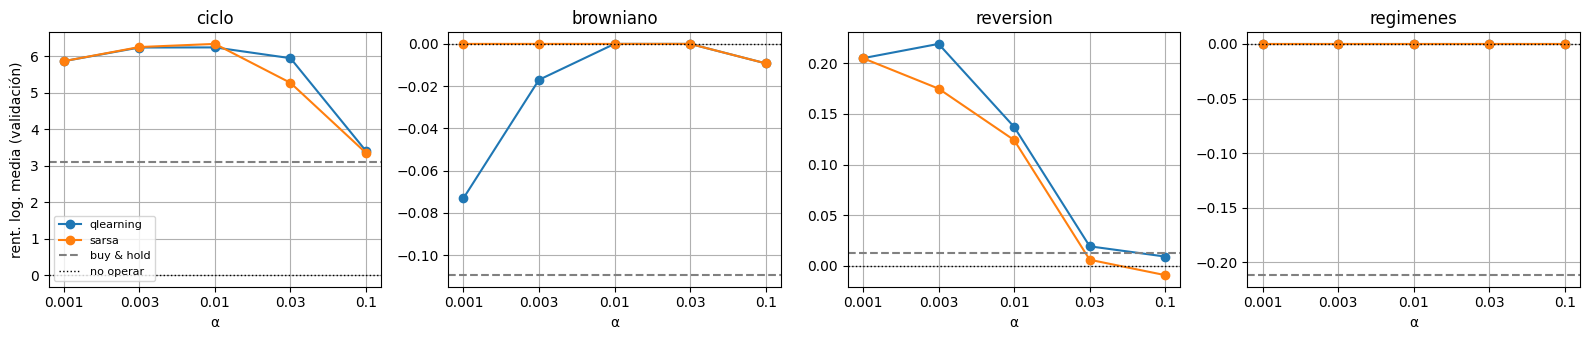

In [33]:
ajustar("alpha", [0.001, 0.003, 0.01, 0.03, 0.1])
grafico_sensibilidad("alpha", "α")

**Resultado.** $\alpha$ es el hiperparámetro que más influye. Con $\alpha = 0.1$ el rendimiento cae en *ciclo* (de 6.3 a 3.3, el nivel de *buy & hold*) y en *reversión* desaparece la ventaja (de 0.22 a 0.01). Los mejores valores están entre 0.001 y 0.01.

**Por qué.** Con $\alpha$ grande, $Q(s, a)$ es prácticamente una media de las últimas recompensas recibidas en ese estado, y esas recompensas son sobre todo ruido: en *reversión* el precio se mueve ~2% por paso, mientras que la señal aprovechable es de décimas de punto. Un $\alpha$ pequeño promedia muchas más experiencias y la señal emerge del ruido. Con $\alpha = 0.001$, en *browniano* Q-Learning todavía no ha aprendido a no operar en 3000 episodios: es demasiado lento.

En *regímenes* y *browniano* casi todos los valores llevan a no operar (puntuación 0), así que el valor elegido en esos casos es el primero del empate y no es significativo.

#### Factor de descuento $\gamma$

gamma: 64 entrenamientos en 200 s


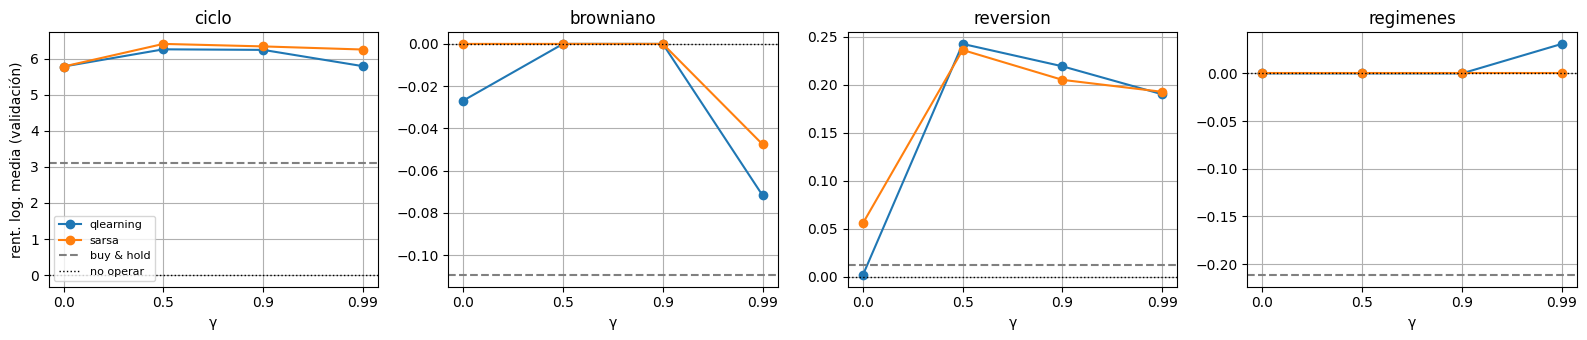

In [34]:
ajustar("gamma", [0.0, 0.5, 0.9, 0.99])
grafico_sensibilidad("gamma", "γ")

**Resultado.** Con $\gamma = 0$ el agente no encuentra la estrategia en *reversión* (0.00–0.06 frente a ~0.24). Con $\gamma = 0.99$ empeora en *browniano* (opera y pierde) y algo en *reversión*. Los mejores valores están en 0.5–0.9.

**Por qué.** Comprar tiene una recompensa inmediata negativa (la comisión) y la ganancia de la reversión llega varios pasos después. Un agente miope ($\gamma = 0$) solo ve el coste. $\gamma$ fija un horizonte efectivo de unos $1/(1-\gamma)$ pasos: 2 con 0.5, 10 con 0.9 y 100 con 0.99. El valor óptimo coincide con el horizonte de la señal (en *reversión*, el retorno esperado tras una caída se acumula en unos 10 pasos). Con $\gamma = 0.99$, $Q$ acumula retornos de pasos muy lejanos que la tendencia actual no predice, lo que solo añade varianza.

En *regímenes*, solo Q-Learning con $\gamma = 0.99$ consigue operar con beneficio: los regímenes duran ~50 pasos de media, y hace falta un horizonte largo para que compense pagar la comisión de entrar.

#### Decaimiento de $\epsilon$

$\epsilon$ baja linealmente de 1 a 0.01 durante una fracción de los episodios (`frac_exploracion`) y después se mantiene en 0.01. Se compara una exploración corta (20%), media (50%) y larga (80%).

frac_exploracion: 48 entrenamientos en 157 s


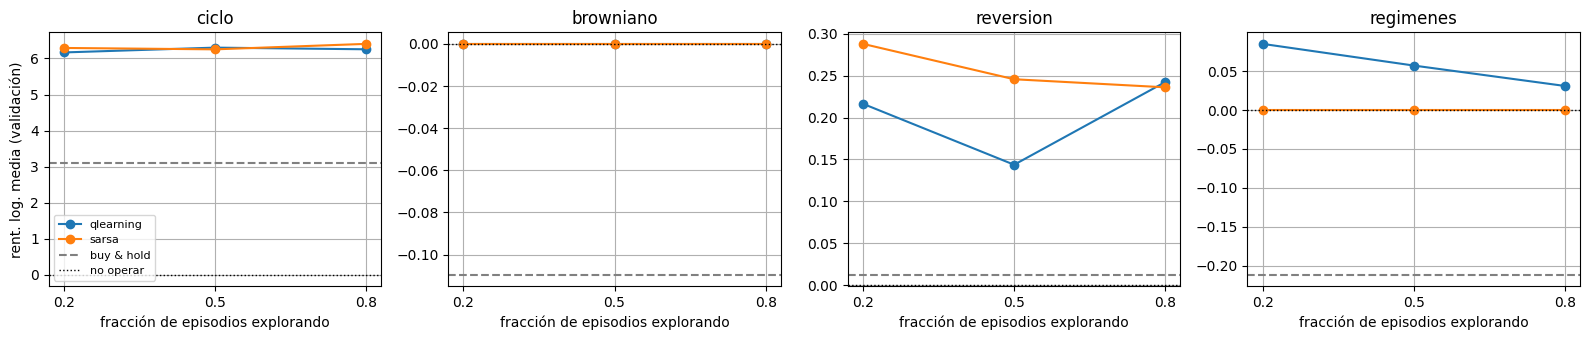

In [35]:
ajustar("frac_exploracion", [0.2, 0.5, 0.8])
grafico_sensibilidad("frac_exploracion", "fracción de episodios explorando")

**Resultado.** El efecto es pequeño comparado con el de $\alpha$ y $\gamma$. En *ciclo* las tres opciones dan prácticamente lo mismo. En *reversión* y *regímenes* las diferencias (~0.05–0.1) son del orden del ruido entre repeticiones; por ejemplo, Q-Learning en *reversión* no es monótono (0.22, 0.14, 0.24).

**Por qué.** El espacio de estados es pequeño (20 estados × 3 acciones) y cada episodio tiene ~500 pasos, así que unos pocos cientos de episodios con $\epsilon$ alto bastan para visitar cada par estado-acción miles de veces. Explorar más no aporta información nueva, y una exploración corta deja más episodios para afinar $Q$ con la política casi voraz.

#### Discretización

Se compara la propuesta de la fase 1 (cuantiles) con distinto número de intervalos y con 10 intervalos iguales en $[-1, 1]$.

discretizacion: 64 entrenamientos en 238 s


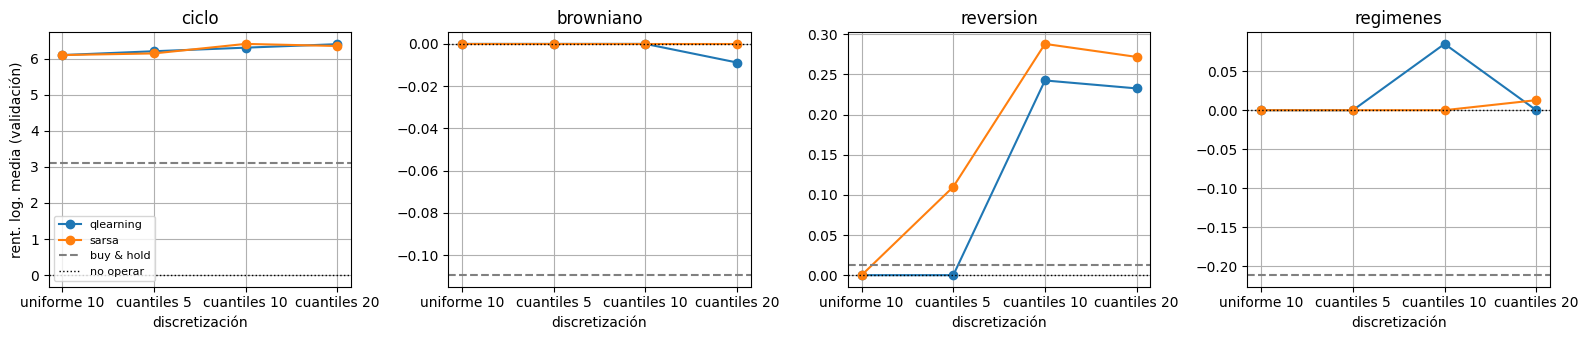

In [36]:
ajustar("discretizacion", ["uniforme 10", "cuantiles 5", "cuantiles 10", "cuantiles 20"])
grafico_sensibilidad("discretizacion", "discretización")

**Resultado.** Los 10 intervalos iguales en $[-1, 1]$ funcionan en *ciclo*, cuya tendencia sí llega a ±0.5, pero en *reversión* dan 0: toda la tendencia cae en los dos intervalos centrales, y el agente no puede distinguir una caída fuerte de una suave, que es justo la señal de ese mercado. Con cuantiles, 10 intervalos funcionan claramente mejor que 5 en *reversión*. Con 20 no se mejora: hay más estados, cada uno recibe menos visitas y $Q$ es más ruidosa.

Esto confirma la decisión de la fase 1. En *browniano* el empate lo gana "uniforme 10", pero da igual, porque el agente no opera.

#### Configuración elegida

In [37]:
tabla_mejor()

alpha gamma frac_exploracion discretizacion
generador algoritmo                                             
ciclo     qlearning   0.01   0.5              0.5   cuantiles 20
          sarsa       0.01   0.5              0.8   cuantiles 10
browniano qlearning   0.01   0.5              0.2    uniforme 10
          sarsa      0.001   0.0              0.2    uniforme 10
reversion qlearning  0.003   0.5              0.8   cuantiles 10
          sarsa      0.001   0.5              0.2   cuantiles 10
regimenes qlearning  0.001  0.99              0.2   cuantiles 10
          sarsa      0.001   0.0              0.2   cuantiles 20

### Fase 4: Convergencia

Con la configuración elegida, cada algoritmo se entrena **5 veces** (repeticiones 10 a 14, distintas de las del ajuste) durante 5000 episodios, evaluando en validación cada 100. Las curvas muestran la media de las 5 repeticiones y una banda de ± una desviación típica.

Para medir la convergencia:

- **Episodios hasta converger:** primer punto de la curva (suavizada con una media móvil de 5 evaluaciones) a partir del cual ya no baja del 90% de la mejora total, es decir, de $v_0 + 0.9 (v_{final} - v_0)$, con $v_{final}$ la media de las 5 últimas evaluaciones. Se calcula para cada repetición.
- **Cambios de política:** número de estados en los que cambia la acción voraz entre dos evaluaciones consecutivas. Si llega a 0, la política se ha estabilizado.
- **Tiempo** de entrenamiento, sin contar las evaluaciones.

In [38]:
N_EP_FINAL = 5000
CADA_FINAL = 100
REPS_FINAL = range(10, 15)

tareas, claves = [], []
for g in GENERADORES:
    for m in ALGORITMOS:
        for rep in REPS_FINAL:
            tareas.append(tarea(g, m, MEJOR[(g, m)], rep, N_EP_FINAL, CADA_FINAL, SERIES_VAL[g]))
            claves.append((g, m))

t0 = time.perf_counter()
resultados = entrenar_en_paralelo(tareas)
print(f"{len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s")

FINAL = {}
for clave, r in zip(claves, resultados):
    FINAL.setdefault(clave, []).append(r)

40 entrenamientos en 305 s


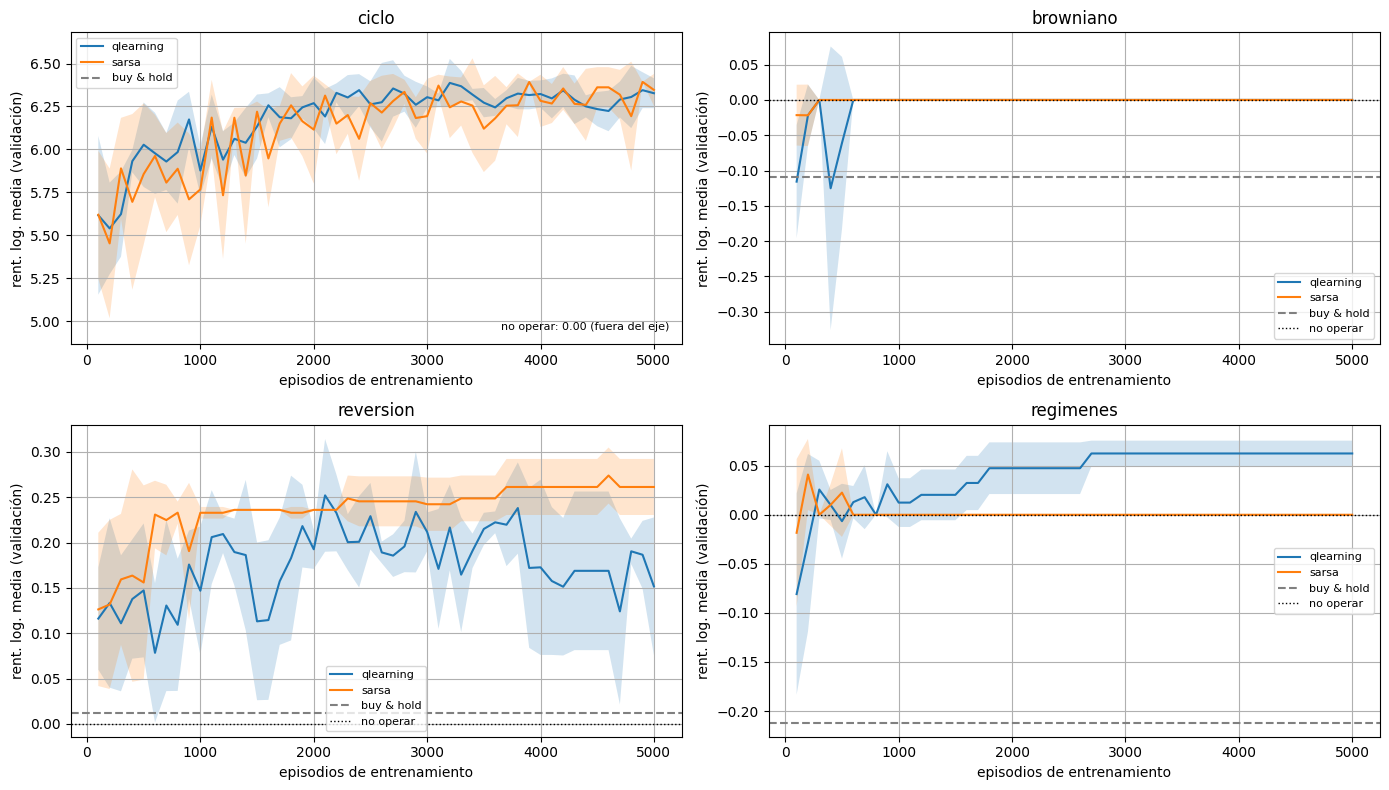

In [39]:
def episodios_hasta_converger(curva, umbral=0.9, ventana=5):
    v = curva["ret_log_medio"].rolling(ventana, min_periods=1).mean().to_numpy()
    v0, vf = v[0], curva["ret_log_medio"].iloc[-5:].mean()
    if vf <= v0:
        return curva["episodio"].iloc[0]
    objetivo = v0 + umbral * (vf - v0)
    por_debajo = np.flatnonzero(v < objetivo)
    i = 0 if len(por_debajo) == 0 else min(por_debajo[-1] + 1, len(v) - 1)
    return curva["episodio"].iloc[i]


def referencia_en_eje(ax, valores, y, **kwargs):
    """Línea horizontal en y si cae cerca de las curvas; si no, el eje se ajusta a las curvas y el valor se escribe."""
    lo, hi = np.min(valores), np.max(valores)
    margen = 0.1 * (hi - lo)
    if lo - 2 * (hi - lo) <= y <= hi + 2 * (hi - lo):
        ax.axhline(y, **kwargs)
    else:
        ax.set_ylim(lo - margen, hi + margen)
        ax.text(0.98, 0.04 + 0.08 * len(ax.texts), f"{kwargs.get('label', '')}: {y:.2f} (fuera del eje)", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=8, color=kwargs.get("color", "black"))


def grafico_convergencia(claves_algoritmos, resultados=None, columna="ret_log_medio", etiqueta="rent. log. media (validación)"):
    resultados = FINAL if resultados is None else resultados
    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    for ax, g in zip(axes.flat, GENERADORES):
        bandas = []
        for m in claves_algoritmos:
            curvas = np.array([r["curva"][columna].to_numpy() for r in resultados[(g, m)]])
            ep = resultados[(g, m)][0]["curva"]["episodio"]
            media, std = curvas.mean(0), curvas.std(0)
            ax.plot(ep, media, label=m)
            ax.fill_between(ep, media - std, media + std, alpha=0.2)
            bandas += [media - std, media + std]
        if columna == "ret_log_medio":
            referencia_en_eje(ax, bandas, REF_VAL[g], color="gray", linestyle="--", label="buy & hold")
            referencia_en_eje(ax, bandas, 0, color="black", linestyle=":", linewidth=1, label="no operar")
        ax.set_title(g)
        ax.set_xlabel("episodios de entrenamiento")
        ax.set_ylabel(etiqueta)
        ax.grid()
        ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


grafico_convergencia(ALGORITMOS)

In [40]:
def resumen_convergencia(claves_algoritmos, resultados=None):
    resultados = FINAL if resultados is None else resultados
    filas = []
    for g in GENERADORES:
        for m in claves_algoritmos:
            res = resultados[(g, m)]
            conv = [episodios_hasta_converger(r["curva"]) for r in res]
            cambios_final = [r["curva"]["cambios_politica"].iloc[-10:].mean() for r in res]
            filas.append({
                "generador": g, "algoritmo": m,
                "episodios_conv_media": np.mean(conv), "episodios_conv_std": np.std(conv),
                "cambios_politica_ultimas_10": np.mean(cambios_final),
                "rent_log_final_val": np.mean([r["curva"]["ret_log_medio"].iloc[-5:].mean() for r in res]),
                "tiempo_s": np.mean([r["tiempo"] for r in res]),
                "ms_por_episodio": 1000 * np.mean([r["tiempo"] for r in res]) / N_EP_FINAL,
            })
    return pd.DataFrame(filas)


CONVERGENCIA = resumen_convergencia(ALGORITMOS)
CONVERGENCIA.round(3)

,generador,algoritmo,episodios_conv_media,episodios_conv_std,cambios_politica_ultimas_10,rent_log_final_val,tiempo_s,ms_por_episodio
0,ciclo,qlearning,3480.0,1445.545,1.52,6.298,138.823,27.765
1,ciclo,sarsa,4540.0,382.623,1.14,6.323,116.442,23.288
2,browniano,qlearning,660.0,313.688,0.00,0.000,115.859,23.172
3,browniano,sarsa,200.0,200.000,0.04,0.000,123.907,24.781
4,reversion,qlearning,2540.0,1736.203,0.48,0.164,124.037,24.807
5,reversion,sarsa,3100.0,1389.964,0.04,0.264,112.250,22.450
6,regimenes,qlearning,1960.0,652.993,0.00,0.062,112.459,22.492
7,regimenes,sarsa,220.0,193.907,0.06,0.000,104.274,20.855


**Resultado** (cada algoritmo con su configuración ajustada):

- **Ciclo:** los dos superan a *buy & hold* desde los primeros 100 episodios, porque la señal es enorme (±10–50% a 10 pasos), y siguen mejorando lentamente hasta el final. Por eso el criterio del 90% da 3500–4500 episodios.
- **Browniano:** los dos aprenden a no operar en menos de 700 episodios y la política se estabiliza (0 cambios).
- **Reversión:** Sarsa sube en ~1000 episodios y se queda estable (0.04 cambios de política por evaluación, banda estrecha). Q-Learning oscila mucho (0.48 cambios, banda ancha) y acaba peor en validación (0.16 frente a 0.26).
- **Regímenes:** Sarsa converge en ~200 episodios a no operar. Q-Learning tarda ~2000 en encontrar una política que gana algo (0.06 en validación).
- **Tiempo:** el coste por paso es el mismo en los dos algoritmos, ~14 ms por episodio en secuencial y ~20–27 ms con 24 procesos en paralelo.

**Atención:** aquí cada algoritmo tiene sus propios hiperparámetros. En *reversión*, Sarsa usa $\alpha = 0.001$ y explora el 20% de los episodios, mientras que Q-Learning usa $\alpha = 0.003$ y explora el 80%. Las diferencias de estabilidad pueden deberse a eso y no al algoritmo; la comparación con los mismos hiperparámetros, más abajo, lo aclara.

#### Recompensa en los episodios de entrenamiento

Como comparación, la recompensa total de cada episodio de entrenamiento (media móvil de 100 episodios y media de las 5 repeticiones). Es mucho más ruidosa que la curva de validación, porque cada episodio usa una serie distinta, y al principio está deprimida por la exploración: sube a medida que baja $\epsilon$ aunque la política voraz no cambie.

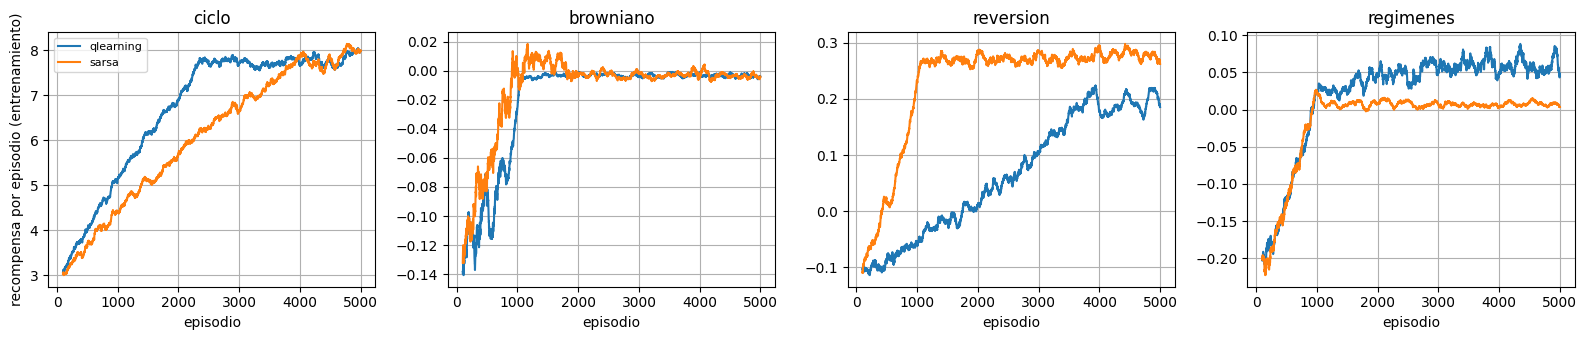

In [41]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, g in zip(axes, GENERADORES):
    for m in ALGORITMOS:
        r = np.array([res["recompensas"] for res in FINAL[(g, m)]]).mean(0)
        ax.plot(pd.Series(r).rolling(100).mean(), label=m)
    ax.set_title(g)
    ax.set_xlabel("episodio")
    ax.grid()
axes[0].set_ylabel("recompensa por episodio (entrenamiento)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Resultado.** La recompensa de entrenamiento tiene un quiebro justo donde $\epsilon$ llega a su mínimo: en el episodio 1000 cuando la exploración dura el 20%, en el 2500 cuando dura el 50% y en el 4000 cuando dura el 80%. Esta curva mide sobre todo **cuánto se explora**, no lo que se ha aprendido. Por ejemplo, en *reversión* Q-Learning (80% explorando) parece aprender mucho más lento que Sarsa (20%), pero en validación la diferencia es mucho menor. Por eso la convergencia se mide en validación.

#### Comparación con los mismos hiperparámetros

En las curvas anteriores cada algoritmo usa su propia configuración, así que parte de las diferencias de velocidad se deben a los hiperparámetros (por ejemplo, a cuántos episodios dura la exploración) y no al algoritmo. Para aislar el efecto del algoritmo, se entrenan los dos con **la misma configuración** en todos los generadores: $\alpha = 0.003$, $\gamma = 0.5$, exploración durante el 50% de los episodios y 10 intervalos por cuantiles (valores intermedios que funcionan bien en el ajuste). Mismas 5 repeticiones y 5000 episodios.

40 entrenamientos en 281 s


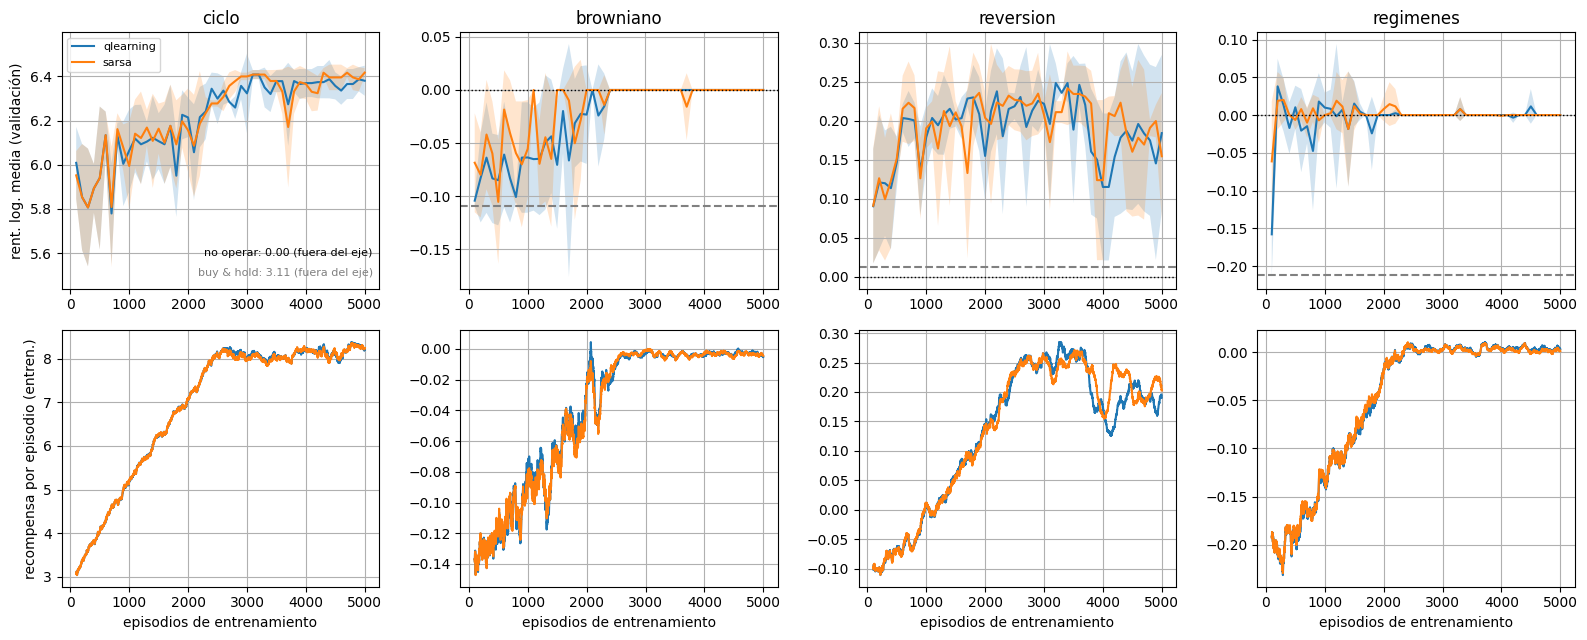

,generador,algoritmo,episodios_conv_media,episodios_conv_std,cambios_politica_ultimas_10,rent_log_final_val,tiempo_s,ms_por_episodio
0,ciclo,qlearning,4100.0,807.465,0.34,6.367,128.707,25.741
1,ciclo,sarsa,4500.0,244.949,0.32,6.402,116.514,23.303
2,browniano,qlearning,2440.0,205.913,0.08,0.000,117.055,23.411
3,browniano,sarsa,2320.0,1319.697,0.16,0.000,120.654,24.131
4,reversion,qlearning,2780.0,2196.725,0.44,0.177,131.637,26.327
5,reversion,sarsa,3500.0,1374.045,0.48,0.179,95.167,19.033
6,regimenes,qlearning,1340.0,624.820,0.08,0.000,95.335,19.067
7,regimenes,sarsa,940.0,845.222,0.06,0.000,85.209,17.042


In [42]:
CONFIG_COMUN = {"alpha": 0.003, "gamma": 0.5, "frac_exploracion": 0.5, "discretizacion": "cuantiles 10"}

tareas, claves = [], []
for g in GENERADORES:
    for m in ALGORITMOS:
        for rep in REPS_FINAL:
            tareas.append(tarea(g, m, CONFIG_COMUN, rep, N_EP_FINAL, CADA_FINAL, SERIES_VAL[g]))
            claves.append((g, m))

t0 = time.perf_counter()
resultados = entrenar_en_paralelo(tareas)
print(f"{len(tareas)} entrenamientos en {time.perf_counter() - t0:.0f} s")

COMUN = {}
for clave, r in zip(claves, resultados):
    COMUN.setdefault(clave, []).append(r)

fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for j, g in enumerate(GENERADORES):
    bandas = []
    for m in ALGORITMOS:
        curvas = np.array([r["curva"]["ret_log_medio"].to_numpy() for r in COMUN[(g, m)]])
        ep = COMUN[(g, m)][0]["curva"]["episodio"]
        axes[0, j].plot(ep, curvas.mean(0), label=m)
        axes[0, j].fill_between(ep, curvas.mean(0) - curvas.std(0), curvas.mean(0) + curvas.std(0), alpha=0.2)
        bandas += [curvas.mean(0) - curvas.std(0), curvas.mean(0) + curvas.std(0)]
        r = np.array([res["recompensas"] for res in COMUN[(g, m)]]).mean(0)
        axes[1, j].plot(pd.Series(r).rolling(100).mean(), label=m)
    referencia_en_eje(axes[0, j], bandas, REF_VAL[g], color="gray", linestyle="--", label="buy & hold")
    referencia_en_eje(axes[0, j], bandas, 0, color="black", linestyle=":", linewidth=1, label="no operar")
    axes[0, j].set_title(g)
    axes[1, j].set_xlabel("episodios de entrenamiento")
    for ax in axes[:, j]:
        ax.grid()
axes[0, 0].set_ylabel("rent. log. media (validación)")
axes[1, 0].set_ylabel("recompensa por episodio (entren.)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

resumen_convergencia(ALGORITMOS, COMUN).round(3)

**Resultado.** Con los mismos hiperparámetros, **Q-Learning y Sarsa son prácticamente indistinguibles** en los cuatro mercados. Las curvas de validación se solapan dentro de la banda de dispersión, las de entrenamiento casi coinciden, y las diferencias en episodios hasta converger (por ejemplo, 2780 ± 2197 frente a 3500 ± 1374 en *reversión*) son mucho menores que la desviación entre repeticiones. Las diferencias de la comparación anterior se deben, por tanto, a los hiperparámetros y no al algoritmo.

**Por qué.**
1. La única diferencia es el valor futuro: $\max_{a'} Q(s', a')$ en Q-Learning y $Q(s', a')$ con $a'$ elegida con $\epsilon$-greedy en Sarsa. Cuando $\epsilon$ es pequeño, $a'$ es casi siempre la acción voraz y los dos objetivos coinciden. La diferencia solo existe durante la exploración.
2. Incluso explorando, aquí una acción aleatoria cuesta poco: como mucho una comisión y un paso de exposición al precio. Es lo contrario del *Cliff Walking* de clase, donde un paso aleatorio junto al acantilado cuesta −100 y por eso Sarsa (que tiene en cuenta sus propios errores de exploración) aprende un camino más seguro que Q-Learning. Sin ese riesgo, el valor de la política $\epsilon$-greedy y el de la voraz son casi iguales.
3. Como las dos versiones usan las mismas semillas, ven exactamente las mismas series de entrenamiento. Por eso sus curvas suben y bajan a la vez, por ejemplo en la caída de *reversión* hacia el episodio 4000.

Esa caída muestra además que, **con $\alpha$ constante, $Q$ no converge a un punto fijo**: sigue moviéndose con las últimas series vistas, y en *reversión* la política sigue cambiando en ~0.45 estados por evaluación al final. Un $\alpha$ más pequeño (como el que eligió el ajuste para Sarsa en *reversión*) o un $\alpha$ decreciente estabilizan la política. Eso explica la mayor estabilidad de Sarsa en la comparación anterior.

### Fase 5: Evaluación en test

Las políticas finales de las 5 repeticiones se evalúan, sin exploración, sobre las 200 series de test de cada generador, que no se han usado en ningún paso anterior. Se dan las medias de las 5 repeticiones y, entre paréntesis en `rent_log_std_reps`, la desviación típica entre repeticiones.

In [43]:
METRICAS = ["balance_medio", "balance_mediana", "ret_log_medio", "pct_gana_bh", "operaciones", "pct_invertido"]


def evaluar_agente_test(g, m):
    cortes = cortes_config(g, MEJOR[(g, m)]["discretizacion"])
    res = [evaluar(politica_voraz(r["Q"], cortes), SERIES_TEST[g]) for r in FINAL[(g, m)]]
    fila = {k: np.mean([x[k] for x in res]) for k in METRICAS}
    fila["rent_log_std_reps"] = np.std([x["ret_log_medio"] for x in res])
    return fila


TEST = {}
for g in GENERADORES:
    TEST[(g, "Aleatorio")] = evaluar(politica_aleatoria, SERIES_TEST[g], semilla=SEMILLA_TEST)
    TEST[(g, "Buy & hold")] = evaluar(politica_buy_and_hold, SERIES_TEST[g])
    for m in ALGORITMOS:
        TEST[(g, m)] = evaluar_agente_test(g, m)

tabla_test = pd.DataFrame([{"generador": g, "agente": a, **{k: v for k, v in res.items() if k != "finales"}}
                           for (g, a), res in TEST.items()])
tabla_test[["generador", "agente"] + METRICAS + ["rent_log_std_reps"]].round(3)

,generador,agente,balance_medio,balance_mediana,ret_log_medio,pct_gana_bh,operaciones,pct_invertido,rent_log_std_reps
0,ciclo,Aleatorio,20195.257,4943.212,1.626,15.0,164.825,49.665,NaN
1,ciclo,Buy & hold,537150.141,25317.789,3.325,0.0,1.000,100.000,NaN
2,ciclo,qlearning,4886925.751,533576.760,6.239,95.8,49.446,53.597,0.067
3,ciclo,sarsa,4397375.802,548471.206,6.254,96.1,46.577,51.936,0.118
4,browniano,Aleatorio,889.192,809.833,-0.169,35.5,164.825,49.665,NaN
5,browniano,Buy & hold,1044.035,931.089,-0.061,0.0,1.000,100.000,NaN
6,browniano,qlearning,1000.000,1000.000,0.000,56.0,0.000,0.000,0.000
7,browniano,sarsa,1000.000,1000.000,0.000,56.0,0.000,0.000,0.000
8,reversion,Aleatorio,906.658,909.927,-0.121,31.5,164.825,49.665,NaN
9,reversion,Buy & hold,990.854,989.253,-0.012,0.0,1.000,100.000,NaN


**Resultado en test** (200 series nuevas):

| Generador | Mejor agente frente a *buy & hold* | Comentario |
|---|---|---|
| **Ciclo** | Balance mediano ~540 000 frente a 25 000; gana a *buy & hold* en el 96% de las series | ~48 operaciones por episodio y ~53% del tiempo invertido: entra y sale con el ciclo |
| **Browniano** | 1000 (no opera) frente a 931 de mediana | No operar gana a *buy & hold* porque este pierde de mediana (volatilidad + comisión), pero no es una ventaja aprovechable: es no jugar |
| **Reversión** | Sarsa: 1271 frente a 989 (+27%); gana a *buy & hold* en el 87% | Q-Learning, 1158 (+16%). ~32 operaciones por episodio |
| **Regímenes** | Q-Learning: 1022 frente a 869; gana a *buy & hold* en el 69% | Sarsa no opera (1000). La ganancia de Q-Learning es pequeña (rentabilidad logarítmica de 0.024) |

Los dos agentes superan al aleatorio en todos los casos; el aleatorio hace ~165 operaciones por episodio y solo en comisiones pierde ~15%. Los resultados de test son muy parecidos a los de validación, así que el ajuste no ha sobreajustado las 50 series de validación (la mayor caída es la de Q-Learning en *regímenes*, de 0.06 a 0.024).

### Fase 6: Análisis por mercado

#### Estrategia esperada

Antes de mirar lo aprendido, lo que cabe esperar de cada generador según cómo está construido:

| Generador | Construcción | Estrategia esperada |
|---|---|---|
| **Ciclo** | Retorno por paso = deriva creciente + $0.05 \sin(t)$ (periodo ≈ 63 pasos) + ruido $N(0, 0.1)$ | Seguir el ciclo: estar dentro cuando la fase es alcista y fuera cuando es bajista. Como la tendencia mide hacia dónde se ha movido el precio en los últimos pasos, comprar con tendencia alta y vender con tendencia baja. |
| **Browniano** | Retornos independientes, deriva casi nula ($\mu = 0.0001$) | No hay nada que predecir: la tendencia no informa del siguiente paso. Lo mejor es no operar o *buy & hold*; como cada operación cuesta una comisión, cualquier estrategia activa debería perder. |
| **Reversión** | El precio vuelve hacia 100 con velocidad $\kappa = 0.05$ | Estrategia contraria: comprar tras una caída (tendencia muy negativa) y vender tras una subida (tendencia muy positiva). |
| **Regímenes** | Alcista ($+0.1\%$, vol. 1%) y bajista ($-0.15\%$, vol. 2.5%), cambia con prob. 0.02 por paso | Seguir la tendencia: dentro en régimen alcista y fuera en el bajista. Pero el régimen bajista se distingue sobre todo por su **volatilidad**, no por la dirección de 6 pasos, así que tendencias extremas en los dos sentidos pueden indicar régimen bajista. |

#### ¿Qué información da la tendencia?

Para comprobar las hipótesis sin depender del agente, se mide con las series de discretización el retorno medio en los 10 pasos siguientes según el intervalo de tendencia (10 intervalos por cuantiles). La línea discontinua marca el coste de una compra y una venta (0.2%).

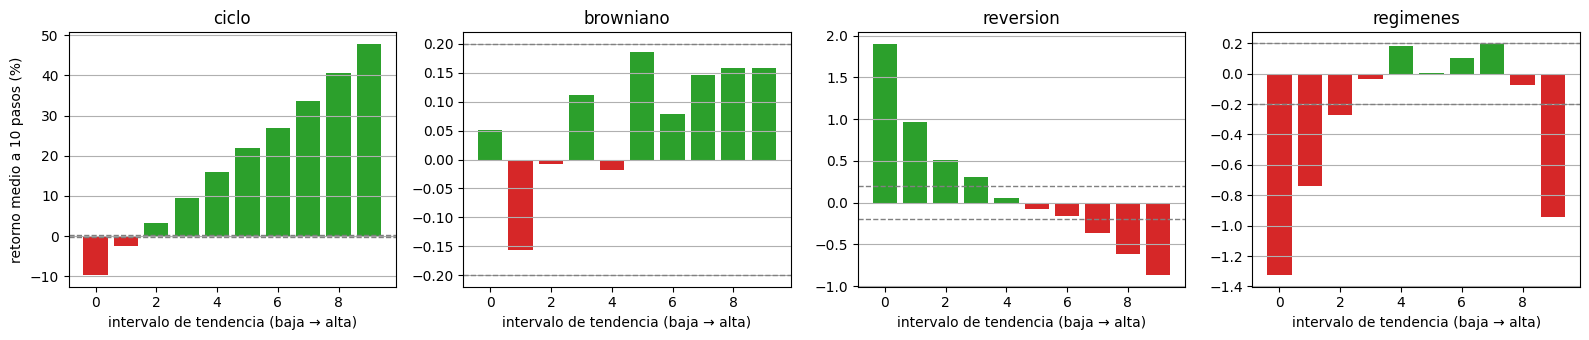

In [44]:
H = 10
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, g in zip(axes, GENERADORES):
    intervalos, futuros = [], []
    for prices in SERIES_DISC[g]:
        t = tendencias_serie(prices)                       # tendencia en los pasos 5 .. n-1
        pasos = np.arange(5, len(prices))
        validos = pasos + H < len(prices)
        intervalos.append(np.searchsorted(CORTES[g], t[validos], side="right"))
        futuros.append(prices[pasos[validos] + H] / prices[pasos[validos]] - 1)
    intervalos, futuros = np.concatenate(intervalos), np.concatenate(futuros)
    medias = [100 * futuros[intervalos == i].mean() for i in range(N_INTERVALOS)]
    ax.bar(range(N_INTERVALOS), medias, color=["tab:green" if v > 0 else "tab:red" for v in medias])
    ax.axhline(0.2, color="gray", linestyle="--", linewidth=1)
    ax.axhline(-0.2, color="gray", linestyle="--", linewidth=1)
    ax.set_title(g)
    ax.set_xlabel("intervalo de tendencia (baja → alta)")
    ax.grid(axis="y")
axes[0].set_ylabel(f"retorno medio a {H} pasos (%)")
plt.tight_layout()
plt.show()

**Resultado.** El gráfico confirma las hipótesis antes de mirar al agente:

- **Ciclo:** el retorno crece de forma monótona con la tendencia (de −10% a +48% en 10 pasos). Hay que seguir la tendencia.
- **Browniano:** no hay ninguna relación distinguible del ruido, y siempre por debajo del coste del 0.2%. No hay nada que aprender.
- **Reversión:** el retorno decrece de forma monótona: +1.9% tras la caída más fuerte y −0.9% tras la subida más fuerte. Solo los intervalos extremos superan el coste, así que la estrategia debe operar poco y solo en los extremos.
- **Regímenes:** forma de **U invertida**. Los dos extremos son negativos (−1.3% y −0.9%), porque una tendencia extrema en cualquier sentido indica volatilidad alta, es decir, régimen bajista. La zona central es ligeramente positiva, pero apenas supera el coste. La señal es débil.

#### Políticas aprendidas

Para cada generador y algoritmo, la acción voraz en cada estado. Se agrupan las acciones equivalentes: sin el activo, vender y mantener son lo mismo (quedarse fuera); con el activo, comprar y mantener son lo mismo (seguir dentro). En cada casilla aparece la acción más frecuente entre las 5 repeticiones y cuántas coinciden con ella; los estados que no se han visitado nunca aparecen en blanco. Con 20 intervalos, V = vende y C = compra.

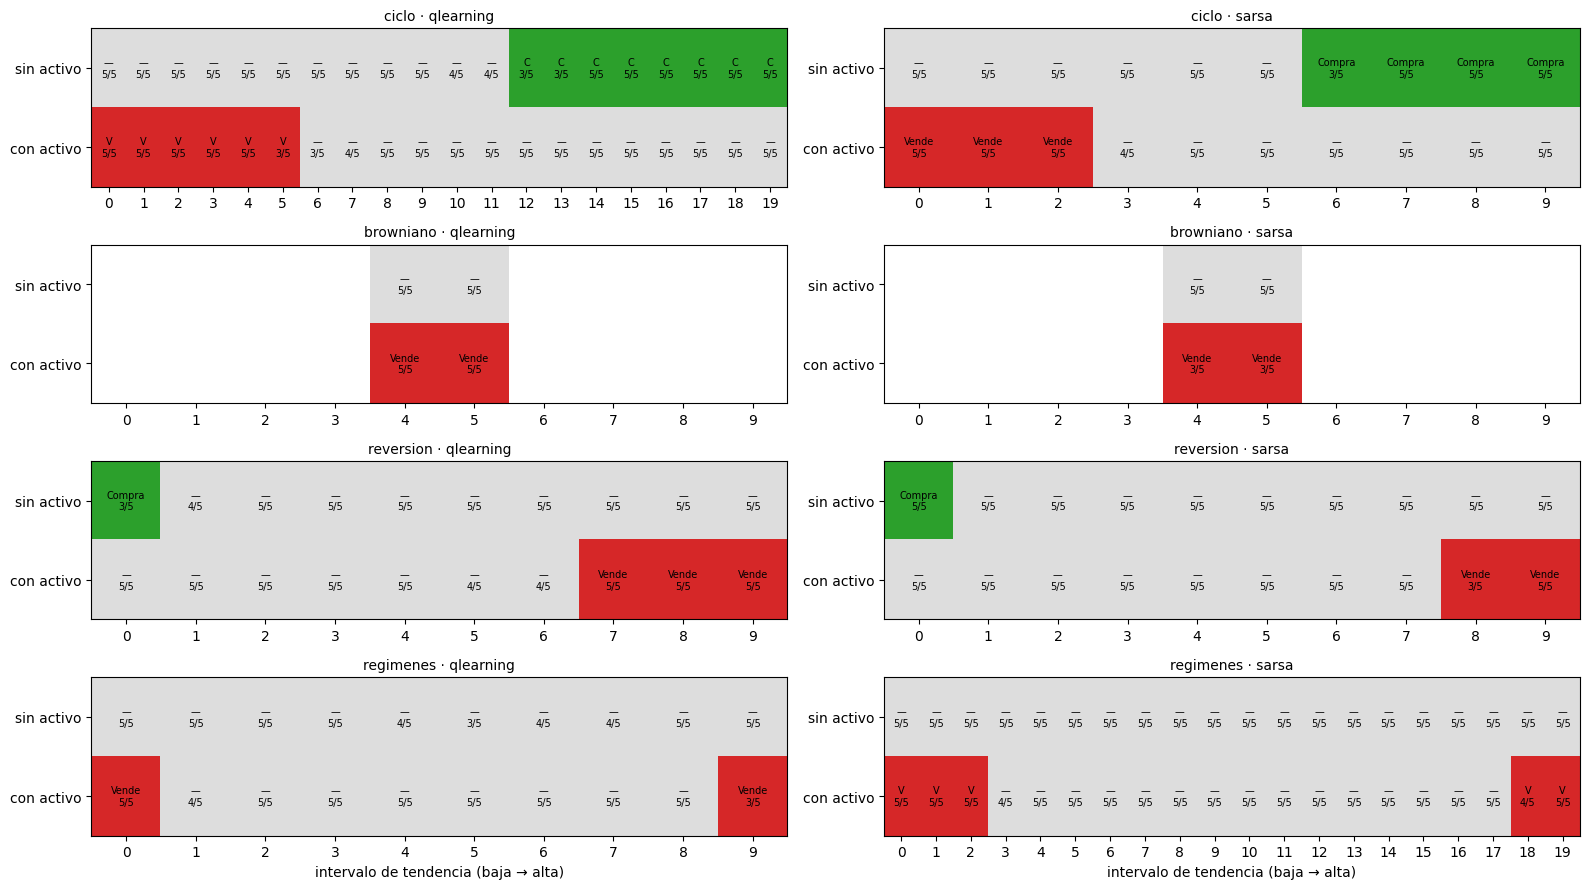

In [45]:
from matplotlib.colors import ListedColormap

ETIQUETAS_EF = {0: "Vende", 1: "—", 2: "Compra"}
ETIQUETAS_CORTAS = {0: "V", 1: "—", 2: "C"}


def politica_consenso(resultados):
    acciones = np.array([acciones_efectivas(r["Q"]) for r in resultados])
    visitados = np.array([np.any(r["Q"] != 0, axis=1) for r in resultados]).any(0)
    moda = np.array([np.bincount(acciones[:, s], minlength=3).argmax() for s in range(acciones.shape[1])])
    acuerdo = (acciones == moda).sum(0)
    return moda, acuerdo, visitados


fig, axes = plt.subplots(4, 2, figsize=(16, 9))
cmap = ListedColormap(["#d62728", "#dddddd", "#2ca02c"])
for fila, g in enumerate(GENERADORES):
    for col, m in enumerate(ALGORITMOS):
        ax = axes[fila, col]
        moda, acuerdo, visitados = politica_consenso(FINAL[(g, m)])
        n = len(moda) // 2
        img = np.where(visitados, moda, np.nan).reshape(2, n).astype(float)
        ax.imshow(img, cmap=cmap, vmin=0, vmax=2, aspect="auto")
        for s in range(2 * n):
            if visitados[s]:
                etiqueta = (ETIQUETAS_EF if n <= 10 else ETIQUETAS_CORTAS)[moda[s]]
                ax.text(s % n, s // n, f"{etiqueta}\n{acuerdo[s]}/5", ha="center", va="center", fontsize=7)
        ax.set_yticks([0, 1], ["sin activo", "con activo"])
        ax.set_xticks(range(n))
        ax.set_title(f"{g} · {m}", fontsize=10)
axes[-1, 0].set_xlabel("intervalo de tendencia (baja → alta)")
axes[-1, 1].set_xlabel("intervalo de tendencia (baja → alta)")
plt.tight_layout()
plt.show()

**Resultado.**

- **Ciclo:** compra con tendencia alta y vende con tendencia baja (seguir el ciclo), con acuerdo 5/5 en casi todos los estados. Entre los dos umbrales hay una **zona en la que mantiene lo que tenga** (con 20 intervalos, Q-Learning compra desde el intervalo 12 y vende hasta el 5). Esa histéresis evita entrar y salir continuamente pagando comisiones.
- **Browniano:** con la discretización uniforme toda la tendencia cae en los intervalos 4 y 5. No compra nunca y, si tuviera el activo, lo vendería. Es la estrategia esperada.
- **Reversión:** exactamente la estrategia contraria esperada. Compra solo tras la caída más fuerte (intervalo 0) y vende tras las subidas fuertes (7–9 en Q-Learning, 8–9 en Sarsa). Entre medias mantiene, con una banda de histéresis muy amplia: entra en un extremo y aguanta hasta el otro.
- **Regímenes:** ninguna compra es mayoritaria. Q-Learning compra en distintos intervalos centrales según la repetición (acuerdo de 3/5–4/5) y Sarsa no compra nunca. En lo que sí coinciden los dos es en **vender con tendencias extremas en los dos sentidos**, como predecía el gráfico anterior: el agente usa la tendencia extrema como señal de volatilidad (régimen bajista), no de dirección. No es la estrategia "seguir la tendencia" que habríamos dicho en un principio, pero es la que tiene sentido con la información que da el estado.

#### Episodio de ejemplo

Primera serie de test de cada generador, jugada con la política de Q-Learning de la primera repetición. Es el mismo gráfico de dos paneles del notebook: arriba el precio, en verde los pasos con el activo y en rojo sin él; abajo el balance del agente frente a *buy & hold*. En *ciclo* los ejes verticales están en escala logarítmica, porque el balance del agente llega a millones y, en escala lineal, *buy & hold* no se distingue de cero.

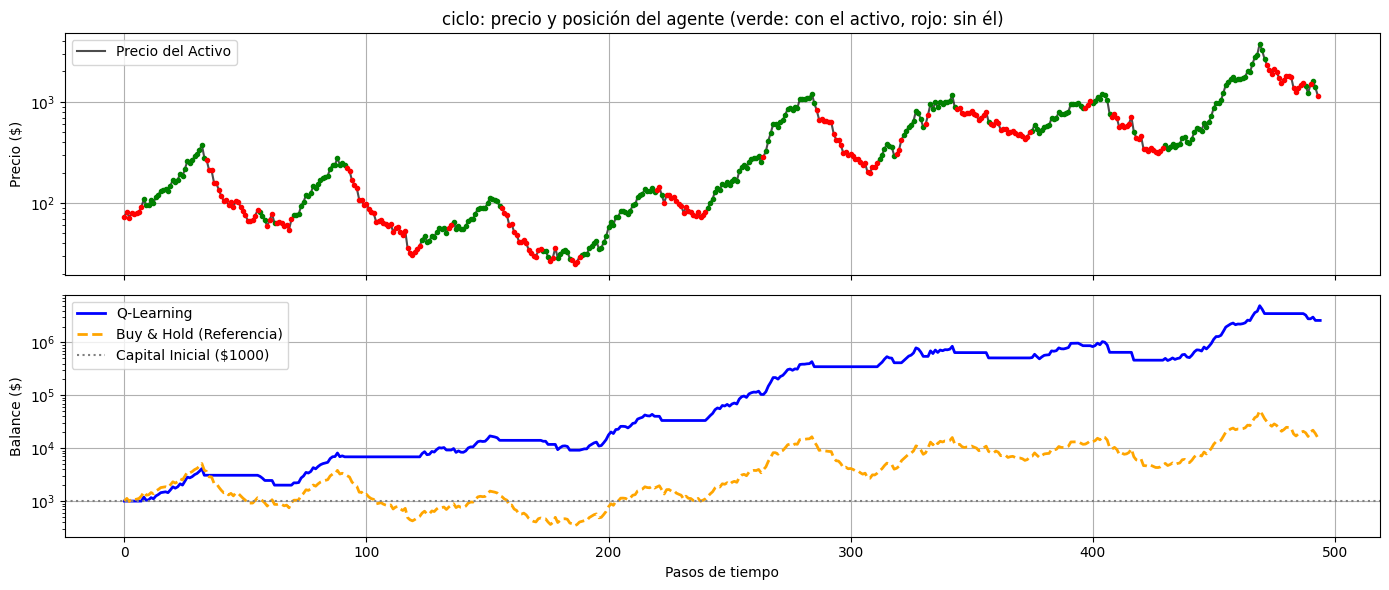

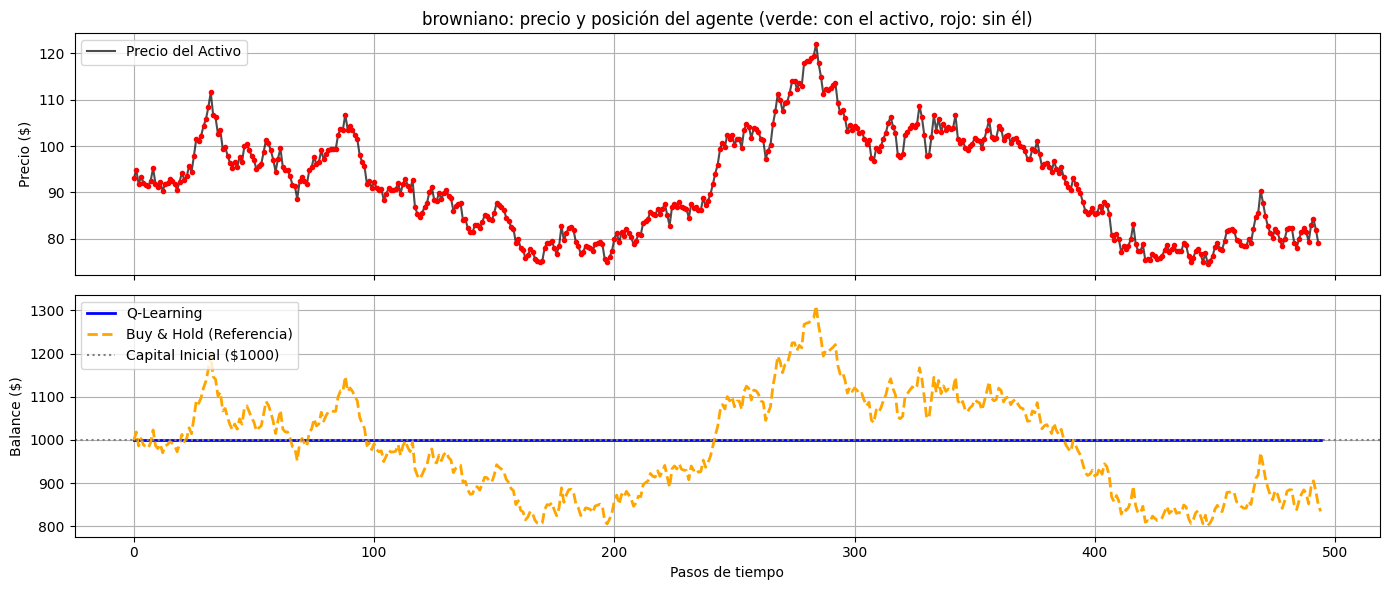

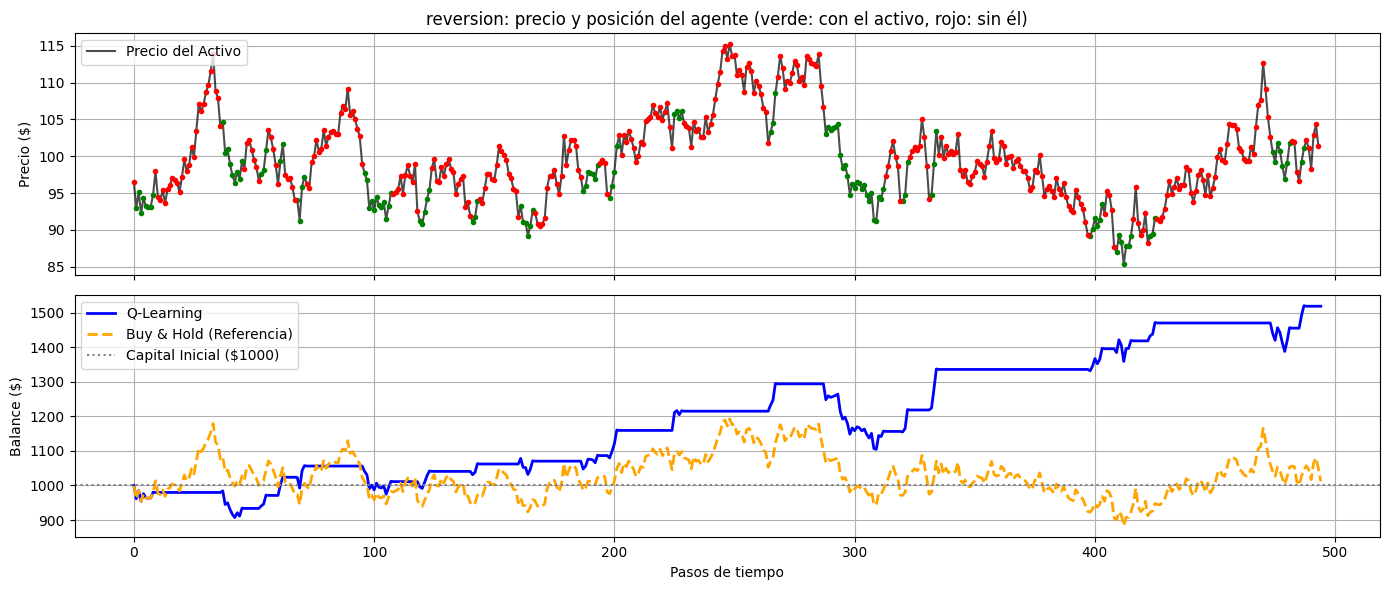

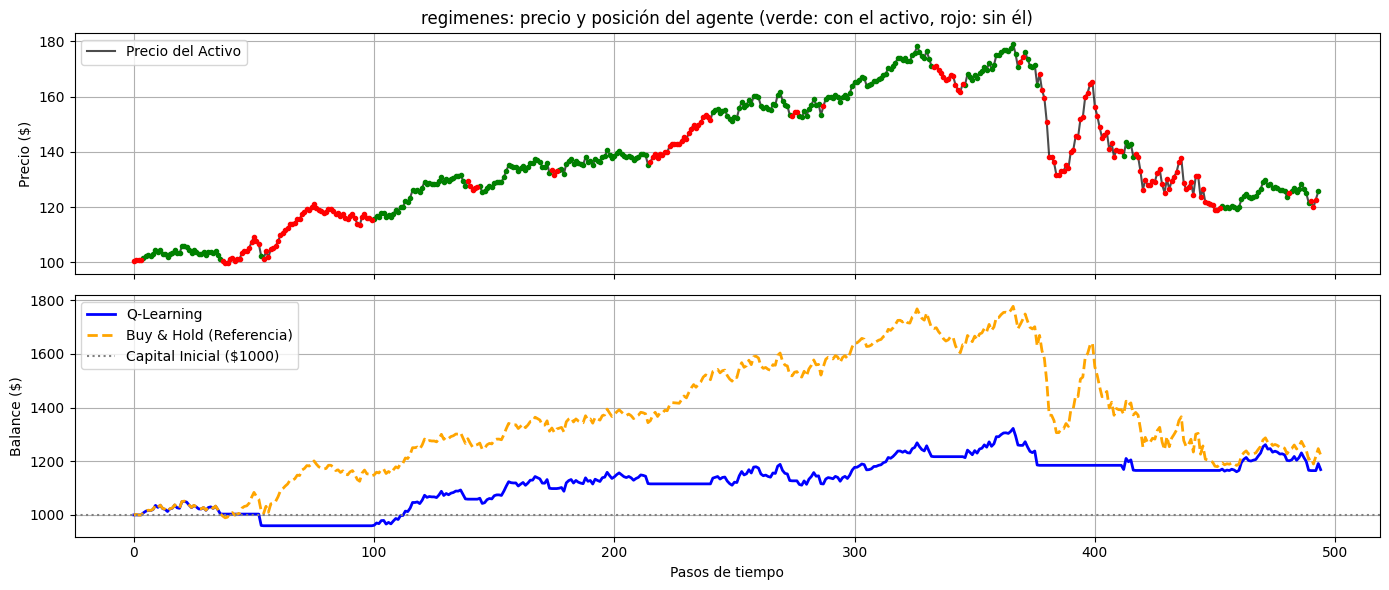

In [46]:
def grafico_episodio(prices, politica, nombre_agente, titulo, escala_log=False):
    balances, acciones, positions = jugar_episodio(prices, politica)
    valid_prices = prices[5:-1]
    prices_on = valid_prices.copy()
    prices_on[positions == 0] = np.nan
    prices_off = valid_prices.copy()
    prices_off[positions == 1] = np.nan

    bh_shares = (1000.0 * 0.999) / prices[5]
    bh_balances = bh_shares * prices[5:]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
    ax1.plot(prices_on, "g.")
    ax1.plot(prices_off, "r.")
    ax1.set_title(titulo)
    ax1.set_ylabel("Precio ($)")
    ax1.legend(loc="upper left")
    ax1.grid(True)

    ax2.plot(balances, label=nombre_agente, color="blue", linewidth=2)
    ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
    ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")
    if escala_log:
        ax1.set_yscale("log")
        ax2.set_yscale("log")
    ax2.set_xlabel("Pasos de tiempo")
    ax2.set_ylabel("Balance ($)")
    ax2.legend(loc="upper left")
    ax2.grid(True)
    plt.tight_layout()
    plt.show()


for g in GENERADORES:
    m = "qlearning"
    cortes = cortes_config(g, MEJOR[(g, m)]["discretizacion"])
    grafico_episodio(SERIES_TEST[g][0], politica_voraz(FINAL[(g, m)][0]["Q"], cortes), "Q-Learning",
                     f"{g}: precio y posición del agente (verde: con el activo, rojo: sin él)",
                     escala_log=(g == "ciclo"))

**Resultado.**

- **Ciclo:** está dentro en las fases alcistas y fuera en las bajistas. Acaba ~100 veces por encima de *buy & hold*.
- **Browniano:** no opera nunca; el balance se queda en 1000 mientras *buy & hold* oscila.
- **Reversión:** compra en los mínimos locales, tras las caídas, y vende tras los rebotes. El balance sube de forma escalonada, con poca exposición.
- **Regímenes:** se mantiene dentro en las subidas tranquilas y sale cuando aumenta la volatilidad (por ejemplo, en la caída brusca hacia el paso 380). Pero también sale en subidas rápidas, porque para el agente una subida brusca también es señal de volatilidad. En esta serie, que es alcista, acaba por debajo de *buy & hold*.

### Fase 7: Tabla final

Resultados en **test** (200 series por generador) y convergencia (5 repeticiones). Para los agentes de RL, las métricas de test son la media de las 5 repeticiones.

In [47]:
filas = []
for g in GENERADORES:
    for a in ["Aleatorio", "Buy & hold"] + list(ALGORITMOS):
        fila = {"generador": g, "agente": a,
                "balance mediano": TEST[(g, a)]["balance_mediana"],
                "rent. log. media": TEST[(g, a)]["ret_log_medio"],
                "% series gana a B&H": TEST[(g, a)]["pct_gana_bh"],
                "operaciones": TEST[(g, a)]["operaciones"]}
        if a in ALGORITMOS:
            c = CONVERGENCIA[(CONVERGENCIA["generador"] == g) & (CONVERGENCIA["algoritmo"] == a)].iloc[0]
            fila["episodios hasta converger"] = f"{c['episodios_conv_media']:.0f} ± {c['episodios_conv_std']:.0f}"
            fila["tiempo (s)"] = c["tiempo_s"]
        filas.append(fila)

TABLA_FINAL = pd.DataFrame(filas).set_index(["generador", "agente"])
TABLA_FINAL.round(3)

balance mediano  rent. log. media  % series gana a B&H  \
generador agente                                                               
ciclo     Aleatorio          4943.212             1.626                 15.0   
          Buy & hold        25317.789             3.325                  0.0   
          qlearning        533576.760             6.239                 95.8   
          sarsa            548471.206             6.254                 96.1   
browniano Aleatorio           809.833            -0.169                 35.5   
          Buy & hold          931.089            -0.061                  0.0   
          qlearning          1000.000             0.000                 56.0   
          sarsa              1000.000             0.000                 56.0   
reversion Aleatorio           909.927            -0.121                 31.5   
          Buy & hold          989.253            -0.012                  0.0   
          qlearning          1158.213             0.143                 77.5   
          sarsa              1270.591             0.234                 87.2   
regimenes Aleatorio           799.997            -0.256                 40.0   
          Buy & hold          869.224            -0.182                  0.0   
          qlearning          1022.318             0.024                 69.3   
          sarsa              1000.000             0.000                 63.0   

                      operaciones episodios hasta converger  tiempo (s)  
generador agente                                                         
ciclo     Aleatorio       164.825                       NaN         NaN  
          Buy & hold        1.000                       NaN         NaN  
          qlearning        49.446               3480 ± 1446     138.823  
          sarsa            46.577                4540 ± 383     116.442  
browniano Aleatorio       164.825                       NaN         NaN  
          Buy & hold        1.000                       NaN         NaN  
          qlearning         0.000                 660 ± 314     115.859  
          sarsa             0.000                 200 ± 200     123.907  
reversion Aleatorio       164.825                       NaN         NaN  
          Buy & hold        1.000                       NaN         NaN  
          qlearning        31.962               2540 ± 1736     124.037  
          sarsa            31.816               3100 ± 1390     112.250  
regimenes Aleatorio       164.825                       NaN         NaN  
          Buy & hold        1.000                       NaN         NaN  
          qlearning        32.418                1960 ± 653     112.459  
          sarsa             0.000                 220 ± 194     104.274

### Fase 8: Datos reales

Se prueban los dos algoritmos con tres mercados reales, con precios diarios de cierre:

- **EUR/USD**: tipo de cambio de la Reserva Federal (FRED, `DEXUSEU`), desde 1999.
- **S&P 500**: índice con dividendos reinvertidos (`^SP500TR`, Yahoo Finance), desde 1988. Sin dividendos, *buy & hold* perdería ~2% al año de forma artificial.
- **Energía**: 10 grandes petroleras (precios ajustados por dividendos y *splits*, Yahoo Finance) y el Brent *spot* (FRED, `DCOILBRENTEU`), en las fechas comunes a las 11 series: desde junio de 2001, cuando sale a bolsa Equinor. Se usa el *spot* y no el futuro `BZ=F`, que solo existe desde 2007 y salta en cada cambio de contrato. Las petroleras son las grandes de hoy, así que hay **sesgo de supervivencia**.

**Diseño del experimento**

- **Bloques de 252 sesiones** (≈ 1 año), consecutivos y sin solaparse. Cada mercado se divide **por fechas**: ~70% de los bloques, los más antiguos, para entrenamiento; el 15% siguiente para validación, y el 15% más reciente para test. En *Energía* el corte es el mismo para las 11 series: si se entrenara con Exxon en 2020 y se probara con Chevron en 2020, el agente ya habría visto ese año, porque las petroleras se mueven juntas.
- **Walk-forward**: cada bloque de validación o test se juega con un agente entrenado con **todas las sesiones anteriores**, dejando un hueco de 50 sesiones (*embargo*) entre el final del entrenamiento y el bloque. Se reentrena para cada bloque, como se haría en la práctica, en lugar de evaluar 4–6 años con un agente entrenado hace años.
- **Episodios de entrenamiento**: bloques de 252 sesiones con inicio al azar dentro del periodo de entrenamiento (en *Energía*, también la serie al azar). Estas ventanas se solapan: no aportan información nueva, solo recorren los mismos datos desde distintos puntos de partida. Validación y test usan los bloques sin solapar.
- **Discretización**: cuantiles calculados, en cada bloque, solo con las sesiones de entrenamiento.
- **Hiperparámetros**: con 4–6 bloques de validación no tiene sentido repetir todo el ajuste de la fase 3. La exploración se fija en lo aprendido con las series sintéticas (50% de 3000 episodios) y se eligen en validación los dos hiperparámetros que más pesaron: $\alpha \in \{0.001, 0.003, 0.01\}$ y $\gamma \in \{0.5, 0.9, 0.99\}$ (horizonte de ~2, 10 y 100 sesiones). 3 repeticiones.
- **Métricas** (test): rentabilidad anual geométrica media de los bloques, % de bloques en que se gana a *buy & hold*, ratio de Sharpe y caída máxima de la curva de capital que encadena los bloques, operaciones por bloque y % del tiempo invertido.

#### Datos

Se guarda una copia local en `datos_reales/` para que el notebook se pueda volver a ejecutar sin conexión y con los mismos datos.

In [48]:
import yfinance as yf
from pathlib import Path

CARPETA_DATOS = Path("datos_reales")
FECHA_FIN = "2026-10-01"
PETROLERAS = ["XOM", "CVX", "SHEL", "TTE", "BP", "COP", "EQNR", "PBR", "E", "OXY"]


def descargar_fred(serie):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={serie}"
    return pd.read_csv(url, index_col=0, parse_dates=True, na_values=".").iloc[:, 0]


def descargar_yahoo(tickers):
    return yf.download(tickers, start="1980-01-01", end=FECHA_FIN, auto_adjust=True, progress=False)["Close"][tickers]


def cargar(nombre, descargar):
    """Lee la copia local o, si no existe, descarga los datos y la guarda."""
    ruta = CARPETA_DATOS / f"{nombre}.csv"
    if not ruta.exists():
        CARPETA_DATOS.mkdir(exist_ok=True)
        descargar().to_csv(ruta)
    return pd.read_csv(ruta, index_col=0, parse_dates=True)


DATOS = {
    "EUR/USD": cargar("eurusd", lambda: descargar_fred("DEXUSEU").to_frame("EUR/USD")),
    "S&P 500": cargar("sp500tr", lambda: descargar_yahoo(["^SP500TR"]).set_axis(["S&P 500 TR"], axis=1)),
    "Energía": cargar("energia", lambda: descargar_yahoo(PETROLERAS).join(
        descargar_fred("DCOILBRENTEU").rename("BRENT"), how="inner")),
}
# Mismo final para todos y solo las fechas con dato en todas las series del mercado
DATOS = {m: d[d.index < FECHA_FIN].dropna() for m, d in DATOS.items()}
PRECIOS = {m: d.to_numpy() for m, d in DATOS.items()}

#### División en bloques

Los bloques se alinean con el final de cada serie, para usar los datos más recientes. Cada bloque va de la sesión `inicio` a la sesión `fin`: el agente opera en las 252 sesiones entre las dos y el bloque siguiente empieza en el `fin` del anterior, así que los bloques se pueden encadenar en una sola curva de capital. Antes del primer bloque se reservan 49 sesiones, las que necesita la tendencia de 50.

In [49]:
L_BLOQUE = 252     # sesiones por bloque (≈ 1 año)
HISTORIA = 49      # sesiones previas que necesita la tendencia de 50 precios
EMBARGO = 50       # sesiones sin usar entre el final del entrenamiento y el bloque evaluado
FRAC_VAL = FRAC_TEST = 0.15


def bloques(n_sesiones):
    """(inicio, fin) de los bloques consecutivos de L_BLOQUE sesiones, alineados con la última sesión."""
    n = (n_sesiones - 1 - HISTORIA) // L_BLOQUE
    ultima = n_sesiones - 1
    return [(ultima - (n - k) * L_BLOQUE, ultima - (n - k - 1) * L_BLOQUE) for k in range(n)]


BLOQUES_VAL, BLOQUES_TEST = {}, {}
filas = []
for m, d in DATOS.items():
    b = bloques(len(d))
    n_test, n_val = round(FRAC_TEST * len(b)), round(FRAC_VAL * len(b))
    BLOQUES_TEST[m] = b[-n_test:]
    BLOQUES_VAL[m] = b[-n_test - n_val:-n_test]
    fecha = lambda i: d.index[i].strftime("%Y-%m-%d")
    filas.append({
        "mercado": m, "series": d.shape[1], "desde": fecha(0), "hasta": fecha(-1), "sesiones": len(d),
        "bloques entren.": len(b) - n_val - n_test,
        "validación": f"{n_val}: {fecha(BLOQUES_VAL[m][0][0])} a {fecha(BLOQUES_VAL[m][-1][1])}",
        "test": f"{n_test}: {fecha(BLOQUES_TEST[m][0][0])} a {fecha(BLOQUES_TEST[m][-1][1])}",
    })
pd.DataFrame(filas).set_index("mercado")

,series,desde,hasta,sesiones,bloques entren.,validación,test
mercado,,,,,,,
EUR/USD,1,1999-01-04,2026-09-30,6958,19,4: 2018-08-30 a 2022-09-19,4: 2022-09-19 a 2026-09-30
S&P 500,1,1988-01-04,2026-09-30,9759,26,6: 2014-09-19 a 2020-09-22,6: 2020-09-22 a 2026-09-30
Energía,11,2001-06-18,2026-09-30,6075,17,3: 2020-08-12 a 2023-09-07,3: 2023-09-07 a 2026-09-30


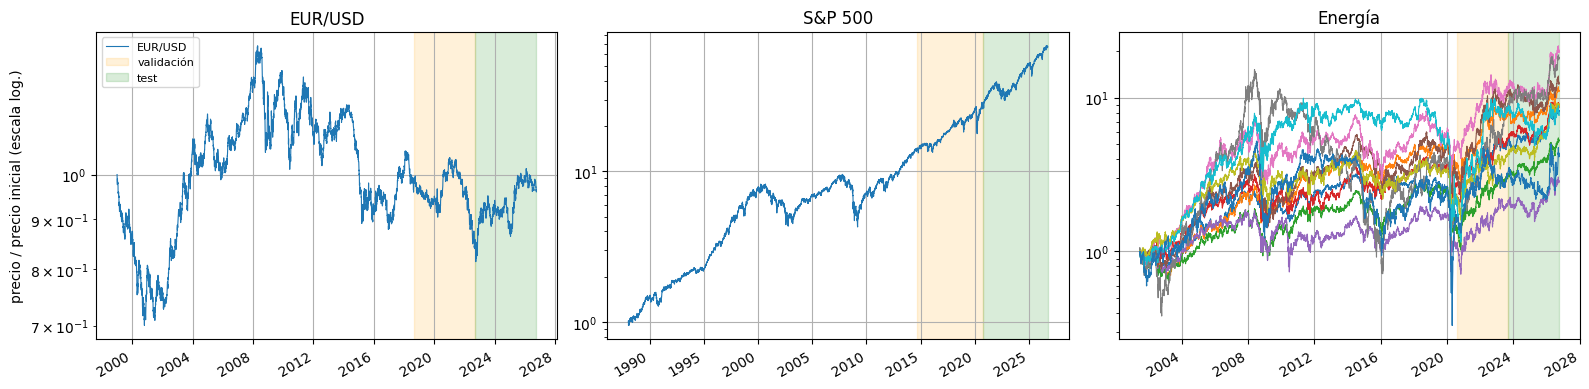

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (m, d) in zip(axes, DATOS.items()):
    (d / d.iloc[0]).plot(ax=ax, logy=True, legend=False, linewidth=0.8)
    ax.axvspan(d.index[BLOQUES_VAL[m][0][0]], d.index[BLOQUES_VAL[m][-1][1]], color="orange", alpha=0.15, label="validación")
    ax.axvspan(d.index[BLOQUES_TEST[m][0][0]], d.index[BLOQUES_TEST[m][-1][1]], color="green", alpha=0.15, label="test")
    ax.set_title(m)
    ax.set_xlabel("")
    ax.grid()
axes[0].set_ylabel("precio / precio inicial (escala log.)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Datos.** EUR/USD tiene 19 bloques de entrenamiento y 4 + 4 de validación y test; S&P 500, 26 y 6 + 6; *Energía*, 17 y 3 + 3 (cada bloque con 11 series). Son muy pocos años de evaluación: los resultados de test dependen de 4–6 años concretos (2020–2026) y hay que leerlos con cautela. Los periodos de test son distintos entre sí: EUR/USD lateral, S&P 500 muy alcista y *Energía* plana hasta 2026, con una fuerte subida al final.

#### Entorno

Se usa el entorno del profesor sin modificarlo, a través de una subclase `EntornoReal` que solo cambia lo necesario para tres variantes:

| Variante | Estado | Estados | Comisión | Mercados |
|---|---|---|---|---|
| profesor | tendencia de 6 precios (10 intervalos) y posición | 20 | 0.1% | los tres |
| dos tendencias | + tendencia de 50 sesiones; 5 × 3 intervalos y posición | 30 | 0.1% | los tres |
| comisión 0.01% | igual que *profesor* | 20 | 0.01% | EUR/USD |

- La tendencia de 50 sesiones usa la misma fórmula que la del entorno: último precio frente a la media. Con 10 × 10 intervalos habría 200 estados, demasiados para unas 5000 sesiones de entrenamiento; por eso 5 × 3.
- La comisión está fijada dentro de `step`. La subclase ejecuta el `step` del profesor y corrige la diferencia en el efectivo, en las acciones y en la recompensa. El 0.1% es irreal en EUR/USD, que se mueve ~0.5% al día y cuesta ~0.01% operarlo.
- Las tres variantes operan en las mismas sesiones de cada bloque. Solo cambia cuántos precios anteriores reciben para calcular la observación.
- Con los valores por defecto, `EntornoReal` es idéntico a `SimpleTradingEnv`; se comprueba abajo.
- El entorno solo permite estar comprado o fuera. En EUR/USD eso significa que solo puede apostar por el euro, nunca por el dólar.

In [51]:
class EntornoReal(SimpleTradingEnv):
    """
    SimpleTradingEnv con dos cambios opcionales:
    - larga: añade a la observación la tendencia de los últimos `larga` precios -> [tendencia, tendencia_larga, posicion].
    - comision: otra comisión por operación en lugar del 0.1% fijo de step.
    """

    def __init__(self, prices, larga=None, comision=0.001):
        super().__init__(prices)
        self.larga = larga
        self.comision = comision

    def reset(self, seed=None):
        super().reset(seed=seed)
        if self.larga is not None:
            self.current_step = self.larga - 1  # suficiente historia para la tendencia larga
        return self._get_obs(), {}

    def _get_obs(self):
        obs = super()._get_obs()
        if self.larga is None:
            return obs
        # max(0, ...): el reset del profesor pide una observación con current_step = 5, que se descarta
        window = self.prices[max(0, self.current_step - self.larga + 1) : self.current_step + 1]
        trend = np.clip((window[-1] - np.mean(window)) / np.mean(window), -1.0, 1.0)
        return np.array([obs[0], trend, obs[1]], dtype=np.float32)

    def step(self, action):
        opera = (action == 2 and self.position == 0) or (action == 0 and self.position == 1)
        obs, reward, terminated, truncated, info = super().step(action)
        if opera and self.comision != 0.001:
            factor = (1 - self.comision) / (1 - 0.001)
            self.shares *= factor  # tras comprar (tras vender shares = 0)
            self.cash *= factor    # tras vender (tras comprar cash = 0)
            reward += 0.001 - self.comision
            self.balance = self.cash + self.shares * self.prices[self.current_step]
            info["balance"] = self.balance
        return obs, reward, terminated, truncated, info


VARIANTES = {
    "profesor": {"entorno": {}, "intervalos": (10,)},
    "dos tendencias": {"entorno": {"larga": 50}, "intervalos": (5, 3)},
    "comisión 0.01%": {"entorno": {"comision": 0.0001}, "intervalos": (10,)},
}
VARIANTES_MERCADO = {
    "EUR/USD": ["profesor", "dos tendencias", "comisión 0.01%"],
    "S&P 500": ["profesor", "dos tendencias"],
    "Energía": ["profesor", "dos tendencias"],
}


def ventana(serie, inicio, fin, entorno):
    """Precios que recibe el entorno para operar de inicio a fin, con la historia que necesita su observación."""
    historia = entorno.get("larga", 6) - 1
    return serie[inicio - historia : fin + 1]

#### Discretización, episodios y evaluación

- `discretizar_real` generaliza `discretizar` a una o dos tendencias. Con una sola da el mismo estado, y la posición sigue siendo la cifra más significativa, así que `acciones_efectivas` sigue valiendo.
- `jugar_real` es `jugar_episodio` con `EntornoReal`. `evaluar_bloque` juega un bloque en cada serie del mercado y guarda el *buy & hold* en el mismo entorno, con la misma comisión.

In [52]:
def tendencia(serie, n_precios):
    """Tendencia en cada sesión con la fórmula de _get_obs: último precio frente a la media de los n últimos."""
    media = pd.Series(serie).rolling(n_precios).mean().to_numpy()
    return np.clip((serie - media) / media, -1.0, 1.0)


def cortes_reales(precios, fin, intervalos):
    """Cortes por cuantiles de cada tendencia (6 y 50 precios) con las sesiones anteriores a fin de todas las series."""
    cortes = []
    for n_intervalos, n_precios in zip(intervalos, (6, 50)):
        t = np.concatenate([tendencia(precios[:fin, j], n_precios)[HISTORIA:] for j in range(precios.shape[1])])
        cortes.append(calcular_cortes(t, n_intervalos))
    return cortes


def n_estados(cortes):
    return 2 * int(np.prod([len(c) + 1 for c in cortes]))


def discretizar_real(obs, cortes):
    """obs = [tendencia, (tendencia_larga,) posicion]; la posición es la cifra más significativa."""
    estado = 0
    for x, c in zip(obs[:-1], cortes):
        estado = estado * (len(c) + 1) + int(np.searchsorted(c, x, side="right"))
    return int(obs[-1]) * (n_estados(cortes) // 2) + estado


def politica_real(Q, cortes):
    def politica(obs, env):
        return int(np.argmax(Q[discretizar_real(obs, cortes)]))
    return politica


def jugar_real(prices, politica, entorno, semilla=None):
    env = EntornoReal(prices, **entorno)
    obs, info = env.reset()
    if semilla is not None:
        env.action_space.seed(semilla)
    balances, operaciones, invertido = [env.balance], 0, 0
    terminated = False
    while not terminated:
        action = politica(obs, env)
        operaciones += (action == 2 and env.position == 0) or (action == 0 and env.position == 1)
        obs, reward, terminated, truncated, info = env.step(action)
        invertido += env.position
        balances.append(env.balance)
    return {"balances": np.array(balances), "operaciones": operaciones,
            "pct_invertido": 100 * invertido / (len(balances) - 1)}


def evaluar_bloque(politica, precios, bloque, variante, semilla=None):
    """Juega el bloque en cada serie del mercado, con el buy & hold de referencia en el mismo entorno."""
    entorno = VARIANTES[variante]["entorno"]
    salida = []
    for j in range(precios.shape[1]):
        prices = ventana(precios[:, j], *bloque, entorno)
        r = jugar_real(prices, politica, entorno, semilla)
        r["bh_final"] = jugar_real(prices, politica_buy_and_hold, entorno)["balances"][-1]
        salida.append(r)
    return salida


# Comprobaciones
serie = PRECIOS["S&P 500"][:600, 0]
for semilla in range(3):
    # Con los valores por defecto, el mismo episodio que con el entorno del profesor
    assert np.array_equal(jugar_episodio(serie, politica_aleatoria, semilla)[0],
                          jugar_real(serie, politica_aleatoria, {}, semilla)["balances"])
    # Con una sola tendencia, el mismo estado que discretizar
    obs = np.array([np.random.default_rng(semilla).normal(0, 0.02), semilla % 2], dtype=np.float32)
    assert discretizar_real(obs, [CORTES["ciclo"]]) == discretizar(obs, CORTES["ciclo"])
# Con comisión del 0.01%, el buy & hold coincide con la fórmula
bh = jugar_real(serie, politica_buy_and_hold, {"comision": 0.0001})["balances"][-1]
assert np.isclose(bh, 1000 * (1 - 0.0001) / serie[5] * serie[-1])
# Las tres variantes operan en las mismas sesiones
b = BLOQUES_TEST["S&P 500"][0]
sesiones = {v: len(jugar_real(ventana(PRECIOS["S&P 500"][:, 0], *b, VARIANTES[v]["entorno"]), politica_buy_and_hold,
                              VARIANTES[v]["entorno"])["balances"]) for v in VARIANTES}
assert set(sesiones.values()) == {L_BLOQUE + 1}, sesiones
print("Comprobaciones correctas")

Comprobaciones correctas


#### Entrenamiento y walk-forward

`entrenar_real` hace la misma actualización que `entrenar` (mismo $\epsilon$-greedy y mismo decaimiento), pero cada episodio es un bloque de 252 sesiones elegido al azar entre las sesiones de entrenamiento. `walk_forward` entrena un agente para cada bloque evaluado, con las sesiones anteriores al bloque menos el embargo, y lo juega en ese bloque.

In [53]:
ALPHAS_REAL = (0.001, 0.003, 0.01)
GAMMAS_REAL = (0.5, 0.9, 0.99)
CONFIG_REAL = {"frac_exploracion": 0.5, "n_episodios": 3000}
REPS_REAL = range(3)


def entrenar_real(metodo, precios, fin, variante, alpha, gamma, frac_exploracion, n_episodios,
                  repeticion=0, eps_inicial=1.0, eps_final=0.01):
    assert metodo in ("qlearning", "sarsa")
    entorno = VARIANTES[variante]["entorno"]
    cortes = cortes_reales(precios, fin, VARIANTES[variante]["intervalos"])
    rng = np.random.default_rng(repeticion)
    Q = np.zeros((n_estados(cortes), N_ACCIONES))

    for ep in range(n_episodios):
        # Serie e inicio al azar; el bloque entero queda antes de fin
        j = rng.integers(precios.shape[1])
        inicio = rng.integers(HISTORIA, fin - L_BLOQUE)
        env = EntornoReal(ventana(precios[:, j], inicio, inicio + L_BLOQUE, entorno), **entorno)
        epsilon = epsilon_episodio(ep, n_episodios, eps_inicial, eps_final, frac_exploracion)

        obs, info = env.reset()
        s = discretizar_real(obs, cortes)
        a = elegir_accion(Q, s, epsilon, rng)
        terminated = False

        while not terminated:
            obs, reward, terminated, truncated, info = env.step(a)
            s2 = discretizar_real(obs, cortes)
            a2 = elegir_accion(Q, s2, epsilon, rng)

            if terminated:
                objetivo = reward
            elif metodo == "qlearning":
                objetivo = reward + gamma * Q[s2].max()
            else:
                objetivo = reward + gamma * Q[s2, a2]

            Q[s, a] += alpha * (objetivo - Q[s, a])
            s, a = s2, a2

    return {"Q": Q, "cortes": cortes}


def tarea_real(mercado, variante, metodo, alpha, gamma, repeticion, bloque):
    precios = PRECIOS[mercado]
    r = entrenar_real(metodo, precios, bloque[0] - EMBARGO, variante, alpha, gamma, repeticion=repeticion, **CONFIG_REAL)
    return evaluar_bloque(politica_real(r["Q"], r["cortes"]), precios, bloque, variante)


def walk_forward(combinaciones, bloques_mercado):
    """
    combinaciones: lista de (mercado, variante, metodo, alpha, gamma).
    Devuelve, para cada combinación, repeticiones -> bloques en orden temporal -> series -> resultado de jugar_real.
    """
    tareas, claves = [], []
    for c in combinaciones:
        for rep in REPS_REAL:
            for bloque in bloques_mercado[c[0]]:
                tareas.append((*c, rep, bloque))
                claves.append((c, rep))
    resultados = Parallel(n_jobs=-1)(delayed(tarea_real)(*t) for t in tareas)
    salida = {}
    for (c, rep), r in zip(claves, resultados):
        salida.setdefault(c, {}).setdefault(rep, []).append(r)
    return {c: list(reps.values()) for c, reps in salida.items()}


def resumir(res):
    """Métricas de cada repetición (sobre todos los bloques y series) y su media."""
    filas = []
    for rep in res:
        finales = np.array([[s["balances"][-1] for s in b] for b in rep])  # bloques x series
        bh = np.array([[s["bh_final"] for s in b] for b in rep])
        sharpe, caida = [], []
        for j in range(finales.shape[1]):
            # Curva de capital de la serie j encadenando sus bloques
            r = np.concatenate([np.diff(np.log(b[j]["balances"])) for b in rep])
            sharpe.append(r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else 0.0)  # sin operar: 0
            capital = np.exp(np.concatenate([[0.0], np.cumsum(r)]))
            caida.append(100 * np.max(1 - capital / np.maximum.accumulate(capital)))
        filas.append({
            "rent_anual_%": 100 * (np.exp(np.log(finales / 1000).mean()) - 1),
            "pct_gana_bh": 100 * np.mean(finales > bh),
            "sharpe": np.mean(sharpe),
            "caida_max_%": np.mean(caida),
            "operaciones": np.mean([[s["operaciones"] for s in b] for b in rep]),
            "pct_invertido": np.mean([[s["pct_invertido"] for s in b] for b in rep]),
        })
    df = pd.DataFrame(filas)
    return {**df.mean().to_dict(), "rent_anual_std_reps": df["rent_anual_%"].std(ddof=0)}


def curva_capital(res):
    """Capital encadenando los bloques: media geométrica sobre repeticiones y series."""
    log_capital = [np.concatenate([[0.0], np.cumsum(np.concatenate([np.diff(np.log(b[j]["balances"])) for b in rep]))])
                   for rep in res for j in range(len(rep[0]))]
    return 1000 * np.exp(np.mean(log_capital, axis=0))


def referencias(bloques_mercado):
    ref = {}
    for m in PRECIOS:
        ref[(m, "Aleatorio")] = [[evaluar_bloque(politica_aleatoria, PRECIOS[m], b, "profesor", semilla=SEMILLA_TEST + k)
                                  for k, b in enumerate(bloques_mercado[m])]]
        ref[(m, "Buy & hold")] = [[evaluar_bloque(politica_buy_and_hold, PRECIOS[m], b, "profesor")
                                   for b in bloques_mercado[m]]]
    return ref

#### Validación: elección de $\alpha$ y $\gamma$

Rentabilidad anual geométrica media (%) en los bloques de validación, media de 3 repeticiones. Si varias combinaciones empatan (por ejemplo, ninguna opera), se queda la primera: el $\gamma$ y el $\alpha$ más pequeños.

In [54]:
combinaciones = [(m, v, a, alpha, gamma) for m in PRECIOS for v in VARIANTES_MERCADO[m]
                 for a in ALGORITMOS for gamma in GAMMAS_REAL for alpha in ALPHAS_REAL]
t0 = time.perf_counter()
VAL_REAL = walk_forward(combinaciones, BLOQUES_VAL)
print(f"{len(combinaciones) * len(REPS_REAL)} combinaciones x repetición, "
      f"{sum(len(BLOQUES_VAL[c[0]]) for c in combinaciones) * len(REPS_REAL)} entrenamientos en {time.perf_counter() - t0:.0f} s")

REF_VAL_REAL = referencias(BLOQUES_VAL)
tabla_val = pd.DataFrame([{"mercado": m, "variante": v, "algoritmo": a, "gamma": gamma, "alpha": alpha,
                           "rent_anual_%": resumir(res)["rent_anual_%"]}
                          for (m, v, a, alpha, gamma), res in VAL_REAL.items()])
tabla_val = tabla_val.pivot_table(index=["mercado", "variante", "algoritmo"], columns=["gamma", "alpha"],
                                  values="rent_anual_%", sort=False)
HIPER_REAL = {clave: {"gamma": gamma, "alpha": alpha} for clave, (gamma, alpha) in tabla_val.idxmax(axis=1).items()}
tabla_val = tabla_val.round(2)
tabla_val["buy & hold"] = [round(resumir(REF_VAL_REAL[(m, "Buy & hold")])["rent_anual_%"], 2) for m, v, a in tabla_val.index]
tabla_val["elegido"] = tabla_val.index.map(lambda c: f"γ={HIPER_REAL[c]['gamma']}, α={HIPER_REAL[c]['alpha']}")
tabla_val


378 combinaciones x repetición, 1620 entrenamientos en 3751 s


gamma                               0.5                0.9               \
alpha                             0.001 0.003  0.01  0.001  0.003  0.01   
mercado variante       algoritmo                                          
EUR/USD profesor       qlearning   0.00  0.00  0.00   0.00   0.00  0.00   
                       sarsa       0.00  0.00  0.00   0.00   0.00  0.00   
        dos tendencias qlearning   0.00  0.00  0.00  -2.79  -1.82  0.41   
                       sarsa       0.00  0.00  0.00   0.00   0.00 -0.19   
        comisión 0.01% qlearning  -0.10  0.00  0.00   0.41  -0.20  0.00   
                       sarsa      -0.24  0.00  0.00   0.10  -0.31  0.00   
S&P 500 profesor       qlearning   7.56  4.51  0.41  11.32  11.57  8.50   
                       sarsa       8.06  2.88  0.22  11.16  10.81  6.03   
        dos tendencias qlearning   7.78  5.36  1.65  10.96  10.71  5.05   
                       sarsa       6.77  2.76  1.70  11.88  10.36  4.23   
Energía profesor       qlearning  19.22  0.00  0.00  37.04  13.08  0.23   
                       sarsa      18.66  0.00  0.00  34.03   5.57  0.00   
        dos tendencias qlearning   9.21  0.29 -0.31  36.82  17.48  2.64   
                       sarsa      13.23  0.40 -0.01  33.39   1.88 -0.26   

gamma                              0.99               buy & hold  \
alpha                             0.001  0.003   0.01              
mercado variante       algoritmo                                   
EUR/USD profesor       qlearning  -1.22  -3.23  -3.26      -3.83   
                       sarsa       0.00   0.00   0.00      -3.83   
        dos tendencias qlearning  -2.43  -4.91  -1.30      -3.83   
                       sarsa       0.40  -1.30  -1.16      -3.83   
        comisión 0.01% qlearning  -1.26  -0.28  -0.27      -3.83   
                       sarsa       0.11   0.02   0.00      -3.83   
S&P 500 profesor       qlearning  11.17  10.93   8.82      10.82   
                       sarsa      12.00  11.56  10.81      10.82   
        dos tendencias qlearning  10.87  10.94  10.22      10.82   
                       sarsa      11.58  11.00   9.54      10.82   
Energía profesor       qlearning  36.66  35.98   5.96      35.85   
                       sarsa      33.29  21.83   1.48      35.85   
        dos tendencias qlearning  36.72  36.24  11.86      35.85   
                       sarsa      33.44  27.70  -2.21      35.85   

gamma                                     elegido  
alpha                                              
mercado variante       algoritmo                   
EUR/USD profesor       qlearning   γ=0.5, α=0.001  
                       sarsa       γ=0.5, α=0.001  
        dos tendencias qlearning    γ=0.9, α=0.01  
                       sarsa      γ=0.99, α=0.001  
        comisión 0.01% qlearning   γ=0.9, α=0.001  
                       sarsa      γ=0.99, α=0.001  
S&P 500 profesor       qlearning   γ=0.9, α=0.003  
                       sarsa      γ=0.99, α=0.001  
        dos tendencias qlearning   γ=0.9, α=0.001  
                       sarsa       γ=0.9, α=0.001  
Energía profesor       qlearning   γ=0.9, α=0.001  
                       sarsa       γ=0.9, α=0.001  
        dos tendencias qlearning   γ=0.9, α=0.001  
                       sarsa      γ=0.99, α=0.001

**Resultado.**

- **$\gamma$ es lo que más cambia el resultado en S&P 500 y Energía.** Con $\gamma = 0.5$ lo mejor es un 7.6–8.1% en S&P 500 y un 19% en *Energía*, lejos de *buy & hold* (10.8% y 35.9%). Con $\gamma = 0.9$–$0.99$ se llega al 11–12% y al 33–37%: el nivel de *buy & hold*. Con un horizonte de ~2 sesiones ($\gamma = 0.5$), el valor de estar dentro solo recoge un par de días de deriva, que es mucho menor que el ruido diario, y el agente sale y entra por ruido. Con un horizonte de 10–100 sesiones la deriva acumulada pesa más que el ruido y que la comisión, y el agente aprende a quedarse dentro.
- **$\alpha$:** sigue ganando el más pequeño (0.001), aunque con $\gamma$ alto 0.003 también funciona. Con 0.01 el resultado cae en todos los casos.
- **EUR/USD:** con $\gamma = 0.5$ el agente no opera nunca. Con $\gamma$ alto empieza a operar y casi siempre pierde (hasta −5% anual); las pocas combinaciones con resultado positivo no pasan del 0.4%. El euro no tiene deriva que recoger, así que un horizonte largo solo añade ruido.
- La variante con dos tendencias no mejora a la del profesor.

#### Test

Cada bloque de test se juega con un agente entrenado con todas las sesiones anteriores (validación incluida), con el $\alpha$ y el $\gamma$ elegidos. Las referencias se juegan en el entorno del profesor; el % de bloques en que se gana a *buy & hold* de la variante con comisión del 0.01% se compara con un *buy & hold* que también paga el 0.01%.

In [55]:
t0 = time.perf_counter()
TEST_REAL = walk_forward([(m, v, a, h["alpha"], h["gamma"]) for (m, v, a), h in HIPER_REAL.items()], BLOQUES_TEST)
print(f"{sum(len(BLOQUES_TEST[m]) for m, v, a in HIPER_REAL) * len(REPS_REAL)} entrenamientos en {time.perf_counter() - t0:.0f} s")
REF_TEST_REAL = referencias(BLOQUES_TEST)

filas = []
for m in PRECIOS:
    for agente in ("Aleatorio", "Buy & hold"):
        filas.append({"mercado": m, "agente": agente, "gamma": "", "alpha": "", **resumir(REF_TEST_REAL[(m, agente)])})
    for (m2, v, a, alpha, gamma), res in TEST_REAL.items():
        if m2 == m:
            filas.append({"mercado": m, "agente": f"{a} ({v})", "gamma": str(gamma), "alpha": str(alpha), **resumir(res)})
TABLA_REAL = pd.DataFrame(filas).set_index(["mercado", "agente"])
TABLA_REAL.round(2)

180 entrenamientos en 421 s


gamma  alpha  rent_anual_%  pct_gana_bh  \
mercado agente                                                               
EUR/USD Aleatorio                                       -5.50         0.00   
        Buy & hold                                       3.09         0.00   
        qlearning (profesor)         0.5  0.001          0.00        25.00   
        sarsa (profesor)             0.5  0.001          0.00        25.00   
        qlearning (dos tendencias)   0.9   0.01          0.00        25.00   
        sarsa (dos tendencias)      0.99  0.001          0.20        25.00   
        qlearning (comisión 0.01%)   0.9  0.001          0.23        25.00   
        sarsa (comisión 0.01%)      0.99  0.001         -0.72        25.00   
S&P 500 Aleatorio                                        5.49        16.67   
        Buy & hold                                      16.51         0.00   
        qlearning (profesor)         0.9  0.003         14.77         5.56   
        sarsa (profesor)            0.99  0.001         16.57        16.67   
        qlearning (dos tendencias)   0.9  0.001         16.43        16.67   
        sarsa (dos tendencias)       0.9  0.001         16.80        38.89   
Energía Aleatorio                                        1.23        24.24   
        Buy & hold                                      13.60         0.00   
        qlearning (profesor)         0.9  0.001         13.41         1.01   
        sarsa (profesor)             0.9  0.001         12.44         2.02   
        qlearning (dos tendencias)   0.9  0.001         12.80         5.05   
        sarsa (dos tendencias)      0.99  0.001         12.90        12.12   

                                    sharpe  caida_max_%  operaciones  \
mercado agente                                                         
EUR/USD Aleatorio                    -1.13        21.09        85.00   
        Buy & hold                    0.42         9.33         1.00   
        qlearning (profesor)          0.00         0.00         0.00   
        sarsa (profesor)              0.00         0.00         0.00   
        qlearning (dos tendencias)    0.00         0.00         0.00   
        sarsa (dos tendencias)        0.08         1.46         0.08   
        qlearning (comisión 0.01%)    0.10         5.63        62.17   
        sarsa (comisión 0.01%)       -0.25         7.33        56.50   
S&P 500 Aleatorio                     0.46        24.40        84.33   
        Buy & hold                    0.93        24.57         1.00   
        qlearning (profesor)          0.85        24.57         3.44   
        sarsa (profesor)              0.93        24.57         1.00   
        qlearning (dos tendencias)    0.92        24.57         1.00   
        sarsa (dos tendencias)        0.95        24.57         1.00   
Energía Aleatorio                     0.11        30.83        86.00   
        Buy & hold                    0.49        29.53         1.00   
        qlearning (profesor)          0.49        29.53         1.00   
        sarsa (profesor)              0.45        29.78         1.00   
        qlearning (dos tendencias)    0.47        29.51         1.00   
        sarsa (dos tendencias)        0.47        29.62         1.00   

                                    pct_invertido  rent_anual_std_reps  
mercado agente                                                          
EUR/USD Aleatorio                           44.35                 0.00  
        Buy & hold                         100.00                 0.00  
        qlearning (profesor)                 0.00                 0.00  
        sarsa (profesor)                     0.00                 0.00  
        qlearning (dos tendencias)           0.00                 0.00  
        sarsa (dos tendencias)               6.75                 0.28  
        qlearning (comisión 0.01%)          22.09                 0.37  
        sarsa (comisión 0.01%)              19.97                 0.45  
S&P

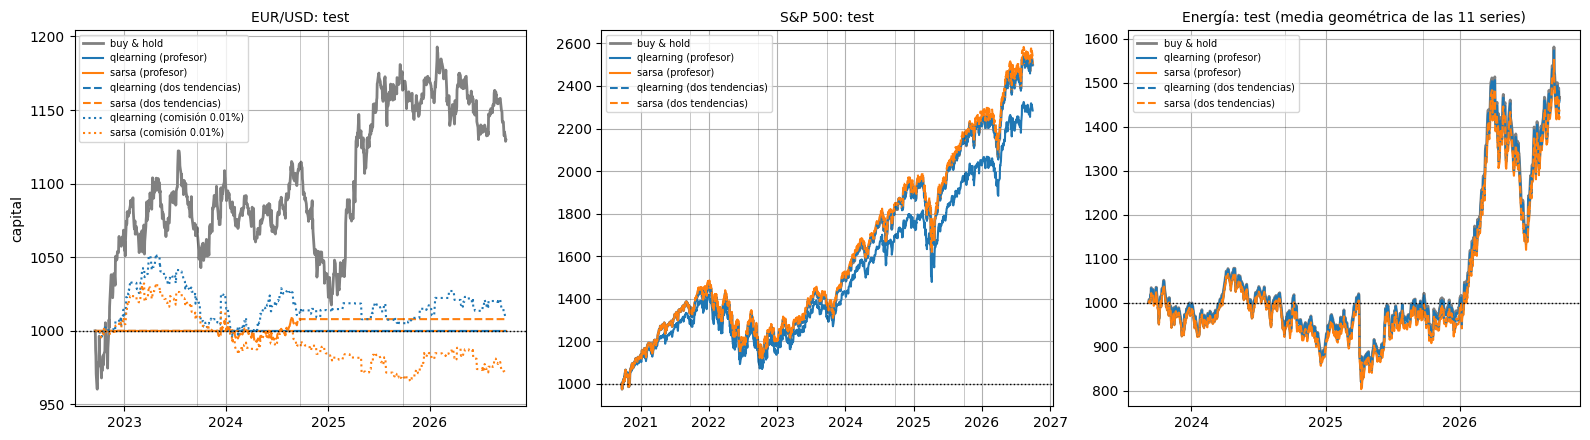

In [56]:
import matplotlib.dates as mdates

ESTILO_VARIANTE = {"profesor": "-", "dos tendencias": "--", "comisión 0.01%": ":"}
COLOR_ALGORITMO = {"qlearning": "C0", "sarsa": "C1"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, m in zip(axes, PRECIOS):
    fechas = DATOS[m].index[BLOQUES_TEST[m][0][0] : BLOQUES_TEST[m][-1][1] + 1]
    ax.plot(fechas, curva_capital(REF_TEST_REAL[(m, "Buy & hold")]), color="gray", linewidth=2, label="buy & hold")
    for (m2, v, a, *_), res in TEST_REAL.items():
        if m2 == m:
            ax.plot(fechas, curva_capital(res), color=COLOR_ALGORITMO[a], linestyle=ESTILO_VARIANTE[v], label=f"{a} ({v})")
    for inicio, fin in BLOQUES_TEST[m][1:]:
        ax.axvline(DATOS[m].index[inicio], color="black", linewidth=0.5, alpha=0.3)
    ax.axhline(1000, color="black", linestyle=":", linewidth=1)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.set_title(f"{m}: test" + (" (media geométrica de las 11 series)" if m == "Energía" else ""), fontsize=10)
    ax.grid()
    ax.legend(fontsize=7)
axes[0].set_ylabel("capital")
plt.tight_layout()
plt.show()

Las líneas verticales separan los bloques; en cada una el agente se ha reentrenado con todo lo anterior. Cada curva es la media geométrica de las 3 repeticiones.

**Resultado en test.**

- **EUR/USD:** con el estado del profesor el agente no opera (0% invertido). Las variantes que sí operan (comisión del 0.01%, ~60 operaciones al año) se quedan en torno a 0 (+0.2% y −0.7%). *Buy & hold* gana un 3.1% anual en test, pero había perdido un 3.8% anual en validación: la tendencia no predice nada y el agente lo detecta.
- **S&P 500:** Sarsa obtiene un 16.6% anual frente al 16.5% de *buy & hold*, con el mismo Sharpe y la misma caída máxima, invertido el 99% del tiempo y con una operación por bloque: **es *buy & hold***. Q-Learning, con el $\alpha$ mayor (0.003), hace ~3 operaciones por bloque y se queda en un 14.8%: alguna salida por ruido. Con dos tendencias, 16.4% y 16.8%: lo mismo.
- **Energía:** los cuatro agentes obtienen un 12.4–13.4% frente al 13.6% de *buy & hold*, con una operación por bloque y ~99% invertidos. La inestabilidad de Sarsa con $\gamma = 0.5$ desaparece (desviación entre repeticiones de 0.2 puntos frente a 5.9).
- **Efecto de $\gamma$:** con $\gamma = 0.5$ fijo (versión anterior de este notebook) el resultado era 17.2% (Q-Learning) y 16.5% (Sarsa) en S&P 500, y 12.1% y 2.6% en *Energía*. Elegir $\gamma$ en validación convierte al agente en un *buy & hold* consistente; la pequeña ventaja de Q-Learning en S&P 500 con $\gamma = 0.5$ era ruido.
- **Conclusión:** con datos diarios reales y este estado, el agente **aprende a no operar o a quedarse dentro siempre**. Los precios reales se comportan casi como el *browniano*: la tendencia de pocos días no predice movimientos mayores que la comisión. En un mercado con deriva positiva, lo mejor que encuentra es estar dentro, y un $\gamma$ alto le ayuda a verlo.

#### Políticas aprendidas con datos reales

Política de Q-Learning en el último bloque de test (el entrenamiento es determinista, así que se vuelve a entrenar el mismo agente). Filas: intervalo de la tendencia, de menor a mayor; columnas: sin activo / con activo. Como en la fase 6, se agrupan las acciones equivalentes y se indica en cuántas de las 3 repeticiones coincide la acción.

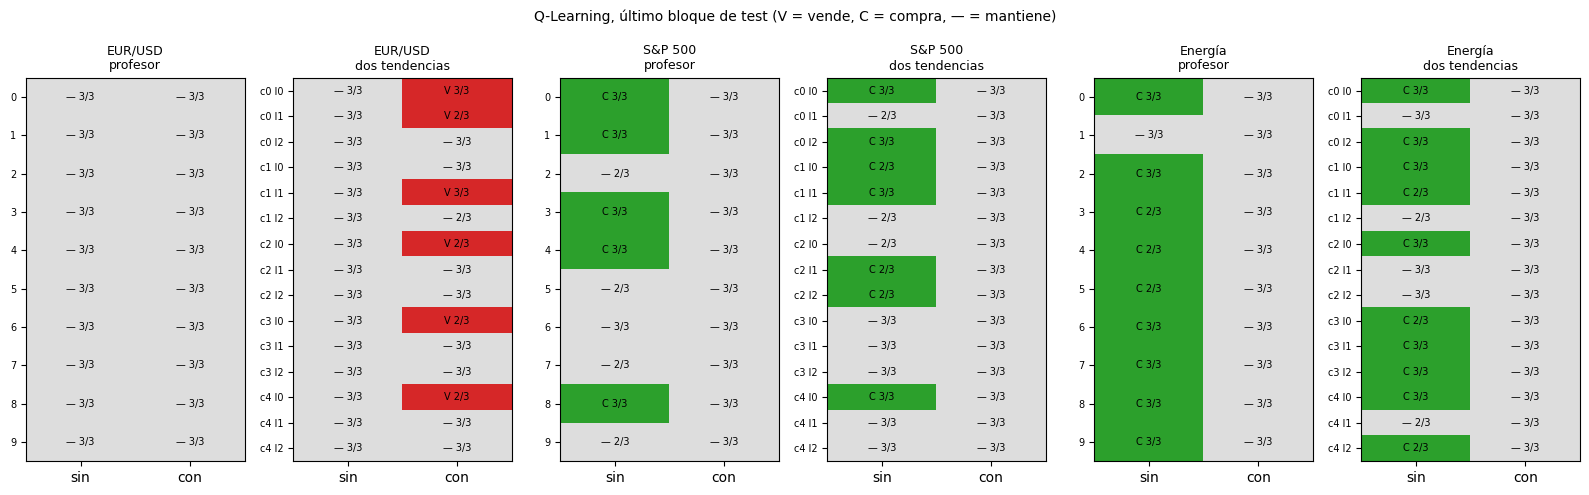

In [57]:
def politica_consenso_real(Qs):
    ef = np.array([acciones_efectivas(Q) for Q in Qs])
    moda = np.array([np.bincount(col, minlength=3).argmax() for col in ef.T])
    acuerdo = (ef == moda).sum(0)
    return moda, acuerdo


paneles = [(m, v) for m in PRECIOS for v in ("profesor", "dos tendencias")]
Qs = Parallel(n_jobs=-1)(
    delayed(entrenar_real)("qlearning", PRECIOS[m], BLOQUES_TEST[m][-1][0] - EMBARGO, v,
                           **HIPER_REAL[(m, v, "qlearning")], repeticion=rep, **CONFIG_REAL)
    for m, v in paneles for rep in REPS_REAL)

fig, axes = plt.subplots(1, 6, figsize=(16, 5))
for k, (ax, (m, v)) in enumerate(zip(axes, paneles)):
    moda, acuerdo = politica_consenso_real([r["Q"] for r in Qs[k * len(REPS_REAL):(k + 1) * len(REPS_REAL)]])
    n = len(moda) // 2
    ax.imshow(moda.reshape(2, n).T, cmap=ListedColormap(["#d62728", "#dddddd", "#2ca02c"]), vmin=0, vmax=2, aspect="auto")
    for s in range(len(moda)):
        ax.text(s // n, s % n, f"{ETIQUETAS_CORTAS[moda[s]]} {acuerdo[s]}/3", ha="center", va="center", fontsize=7)
    if v == "dos tendencias":
        ax.set_yticks(range(n), [f"c{i // 3} l{i % 3}" for i in range(n)], fontsize=7)
    else:
        ax.set_yticks(range(n), range(n), fontsize=7)
    ax.set_xticks([0, 1], ["sin", "con"])
    ax.set_title(f"{m}\n{v}", fontsize=9)
plt.suptitle("Q-Learning, último bloque de test (V = vende, C = compra, — = mantiene)", fontsize=10)
plt.tight_layout()
plt.show()

En *dos tendencias*, `c` es el intervalo de la tendencia de 6 precios (0 a 4) y `l` el de la tendencia de 50 (0 a 2).

**Resultado** (con el $\gamma$ elegido, 0.9 en los cuatro paneles de S&P 500 y *Energía*):

- **EUR/USD:** sin activo, "mantener" en todos los estados: nunca compra. En *dos tendencias* aparecen ventas con el activo, pero no importan porque nunca llega a comprar.
- **S&P 500 y Energía:** compra en la mayoría de los intervalos de tendencia, con acuerdo 3/3 en casi todos, y **con el activo no vende en ningún estado**. La regla es "compra en cuanto puedas y no vendas": *buy & hold*. Con $\gamma = 0.5$ cada repetición compraba en un único intervalo distinto (diferencias de $Q$ de puro ruido); con $\gamma = 0.9$ el valor de estar dentro es claramente mayor y la política coincide entre repeticiones.
- En ningún mercado aparece una regla de venta: una vez dentro, salir solo cuesta la comisión y pierde la deriva positiva del mercado.

#### Agentes entrenados con series sintéticas

Las políticas finales de la fase 4 (5 repeticiones por generador y algoritmo) se juegan, sin reentrenar, en los mismos bloques de test, con el entorno del profesor. Solo se puede hacer con la variante del profesor: las otras cambian el estado o la comisión.

Hay dos formas de traducir la tendencia real a los estados de esas tablas:

- **Cortes originales**: los del generador con el que se entrenaron. Son los cortes de series con ruido del 2% (y del 10% en *ciclo*), mucho más anchos que la tendencia diaria real, así que casi todas las observaciones caen en los intervalos centrales.
- **Cortes recalculados**: los cuantiles de la tendencia real con las sesiones de entrenamiento. Como la tabla se aprendió por cuantiles, el estado significa "decil de la tendencia" y la política se traslada como "compra en el decil más alto", etc. No aplica a *browniano*, que usa intervalos iguales.

In [58]:
filas = []
for m in PRECIOS:
    bh = resumir(REF_TEST_REAL[(m, "Buy & hold")])
    filas.append({"mercado": m, "agente": "Buy & hold", "cortes": "", "rent_anual_%": bh["rent_anual_%"],
                  "pct_gana_bh": np.nan, "operaciones": 0.0, "pct_invertido": bh["pct_invertido"]})
    for g in GENERADORES:
        for a in ALGORITMOS:
            disc = MEJOR[(g, a)]["discretizacion"]
            tipo, n = disc.split()
            for modo in ("originales", "recalculados"):
                if modo == "recalculados" and tipo == "uniforme":
                    continue
                res = []
                for r in FINAL[(g, a)]:
                    bloques_rep = []
                    for bloque in BLOQUES_TEST[m]:
                        cortes = (cortes_config(g, disc) if modo == "originales"
                                  else cortes_reales(PRECIOS[m], bloque[0] - EMBARGO, (int(n),))[0])
                        bloques_rep.append(evaluar_bloque(politica_voraz(r["Q"], cortes), PRECIOS[m], bloque, "profesor"))
                    res.append(bloques_rep)
                resumen = resumir(res)
                filas.append({"mercado": m, "agente": f"{a} ({g})", "cortes": modo,
                              **{k: resumen[k] for k in ("rent_anual_%", "pct_gana_bh", "operaciones", "pct_invertido")}})

SINTETICOS = pd.DataFrame(filas)
SINTETICOS.pivot_table(index=["agente", "cortes"], columns="mercado",
                       values=["rent_anual_%", "pct_invertido"], sort=False).round(1)

rent_anual_%                 pct_invertido  \
mercado                                 EUR/USD S&P 500 Energía       EUR/USD   
agente                cortes                                                    
Buy & hold                                  3.1    16.5    13.6         100.0   
qlearning (ciclo)     originales            0.7     2.3     4.4           7.6   
                      recalculados         -1.2     1.3     4.3          54.9   
sarsa (ciclo)         originales            0.0     0.0     2.3           0.0   
                      recalculados         -1.1     1.3     4.7          53.2   
qlearning (browniano) originales            0.0     0.0     0.0           0.0   
sarsa (browniano)     originales            0.0     0.0     0.0           0.0   
qlearning (reversion) originales            0.2     3.6     2.8           0.1   
                      recalculados          1.0     5.8     2.3          18.9   
sarsa (reversion)     originales            0.0     4.1     5.2           0.0   
                      recalculados          2.3     9.7     3.4          35.1   
qlearning (regimenes) originales            3.9    11.5     2.9          92.6   
                      recalculados         -0.3    -0.1     1.7          65.2   
sarsa (regimenes)     originales            0.0     0.0     0.0           0.0   
                      recalculados          0.0     0.0     0.0           0.0   

                                                    
mercado                            S&P 500 Energía  
agente                cortes                        
Buy & hold                           100.0   100.0  
qlearning (ciclo)     originales      18.5    26.8  
                      recalculados    57.7    54.7  
sarsa (ciclo)         originales       0.0     7.2  
                      recalculados    56.6    52.8  
qlearning (browniano) originales       0.0     0.0  
sarsa (browniano)     originales       0.0     0.0  
qlearning (reversion) originales       4.8    17.3  
                      recalculados    18.8    20.9  
sarsa (reversion)     originales       6.4    31.3  
                      recalculados    31.4    33.8  
qlearning (regimenes) originales      83.6    50.1  
                      recalculados    47.5    50.5  
sarsa (regimenes)     originales       0.0     0.0  
                      recalculados     0.0     0.0

**Resultado.** Ningún agente entrenado con series sintéticas supera a *buy & hold* en ningún mercado real.

- **Ciclo** (seguir la tendencia): con los cortes recalculados opera mucho y pierde en EUR/USD (−1.2%) y apenas gana en S&P 500 (1.3% frente a 16.5%). El *momentum* de 6 días que aprendió no existe en los datos diarios reales.
- **Reversión** (estrategia contraria): es la que mejor se traslada. Sarsa con cortes recalculados obtiene un 9.7% en S&P 500 y un 2.3% en EUR/USD (el mejor de todos ahí). Comprar tras caídas cortas tiene algo de sentido en la bolsa, pero está fuera del mercado dos tercios del tiempo y se pierde la subida.
- **Regímenes:** Q-Learning con sus cortes originales da un 11.5% en S&P 500 porque está dentro el 84% del tiempo: los cortes originales son tan anchos que casi todas las observaciones reales caen en los intervalos donde mantiene la posición.
- **Browniano** y Sarsa en *regímenes* no operan nunca, como en sus mercados de origen.
- **Cortes originales frente a recalculados:** con los originales casi todo cae en los intervalos centrales y el agente hace casi siempre lo mismo. Con los recalculados la política se aplica tal cual ("compra en el decil más alto"), y lo que se ve es si la estrategia sirve en el mercado real: en general, no.

Lo aprendido depende del mercado: las estrategias sintéticas solo funcionan donde existe la regularidad que las generó.

### Conclusiones

1. **El agente aprende en cada mercado la estrategia que tiene sentido con la información que le da el estado.** Sigue el ciclo en *ciclo*, no opera en *browniano*, aplica la estrategia contraria en *reversión* y, en *regímenes*, sale con tendencias extremas (señal de volatilidad). Supera a *buy & hold* en los cuatro mercados, aunque en *browniano* lo hace sin operar y en *regímenes* la ventaja es pequeña. El gráfico del retorno por intervalo de tendencia permite anticipar el resultado: el agente solo encuentra ventaja donde la tendencia predice retornos mayores que la comisión.
2. **Decisiones de diseño que más pesan:**
   - La discretización por cuantiles: sin ella no hay estrategia en *reversión*.
   - Un $\alpha$ pequeño (0.001–0.01), por la relación señal/ruido de los retornos.
   - Un $\gamma$ intermedio (0.5–0.9), acorde con el horizonte de la señal.
   - El decaimiento de $\epsilon$ apenas influye.
3. **Q-Learning frente a Sarsa:** con los mismos hiperparámetros convergen igual de rápido y llegan al mismo resultado. Con $\epsilon$ pequeño sus objetivos coinciden, y en este entorno explorar es barato (no hay "acantilado"). Las diferencias aparentes vienen de los hiperparámetros. Con $\alpha$ constante, $Q$ no converge del todo: sigue fluctuando con las últimas series vistas.
4. **Datos reales:** se comportan como *browniano*, no como los generadores con señal.
   - En EUR/USD el agente no opera; en S&P 500 y en las petroleras aprende a estar siempre dentro y empata con *buy & hold* (16.6% frente a 16.5% en S&P 500; 12.4–13.4% frente a 13.6% en *Energía*).
   - $\gamma$ es el hiperparámetro decisivo en datos reales: con $\gamma = 0.9$–$0.99$ el agente ve la deriva acumulada y se queda dentro de forma estable; con $\gamma = 0.5$ entra y sale por ruido.
   - Añadir la tendencia de 50 sesiones no ayuda: más estados con los mismos pocos datos.
   - Los agentes entrenados con series sintéticas no se trasladan; la estrategia contraria de *reversión* es la que menos pierde.
   - Con 4–6 años de test y mercados que cambian, ninguna diferencia frente a *buy & hold* es concluyente.
5. **Limitaciones:**
   - El estado es muy pobre: solo la tendencia de 6 pasos y la posición. No observa la fase del ciclo ni la volatilidad, que es lo que identifica el régimen, así que el problema **no es markoviano** en ese estado.
   - El generador *ciclo* no es estacionario: su deriva crece con el tiempo y su ruido es del 10% por paso.
   - Pocos datos reales (~20 años por mercado) para una tabla Q, y sesgo de supervivencia en las petroleras.
   - Mejoras naturales: añadir la volatilidad al estado, usar un $\alpha$ decreciente o aproximar $Q$ con una función en lugar de una tabla.